# Solutions to the exercises (notebooks 01-05)

This notebook contains worked solutions to **all exercises** of the course. For each exercise you will find:

1. the exercise, as it was asked;
2. **the approach**: how to tackle it and why;
3. **the code**;
4. **the results, explained in detail**: what the numbers mean, why they come out this way, and what to remember.

**How to read the numbers.** The explanations quote the numbers from the run saved in this notebook. If you re-run it, most numbers come out the same, but some may differ by about a percentage point. Results also shift a little between computers and library versions. Notebook 01 explains why differences below ~1 point are noise. Where it matters, the solutions average over several seeds.

**Running time.** About 6-8 minutes on a laptop CPU for the whole notebook. Run the setup cell first; after that, every part (01, 02, …) can be run on its own, except that part 05 uses the small datasets prepared at the start of part 04.

> **For instructors:** this notebook lives in `solutions/`, outside `notebooks/`, so you can easily leave it out when you hand out the course.

## Setup

The same data and helper functions as in the course notebooks. `train_mlp` is a small shortcut: create an MLP with a fixed seed and train it (with augmentation, quietly). `test_acc` measures test accuracy.

In [1]:
import sys, pathlib, copy, time
ROOT = pathlib.Path.cwd()
while not (ROOT / "aiedge").is_dir() and ROOT != ROOT.parent:   # find the project folder
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import torch
import matplotlib.pyplot as plt

from aiedge import config as C
from aiedge.data import load_gesture_data, limit_training_data, GestureData
from aiedge.models import MLP, ConvNet, count_params, count_macs
from aiedge.training import train, accuracy, set_seed
from aiedge.pruning import (magnitude_masks, sparsity_of, neuron_importance, remove_neurons,
                            prune_neurons)
from aiedge.quantization import QuantMLP, int8_forward, int8_accuracy, int8_model_bytes
from aiedge import plots

T0 = time.time()
data = load_gesture_data()

def train_mlp(hidden=(64, 32), seed=0, train_data=None, **kw):
    """Create an MLP with a fixed seed and train it (augmentation on, quiet, unless overridden)."""
    kw.setdefault("augment", True)
    kw.setdefault("verbose", False)
    set_seed(seed)
    m = MLP(hidden=hidden, in_features=(train_data or data).X_train.shape[1])
    hist = train(m, train_data or data, seed=seed, **kw)
    return m, hist

def test_acc(m, d=None):
    d = d or data
    return accuracy(m, d.X_test, d.y_test)

baseline, _ = train_mlp()
base_acc = test_acc(baseline)
print(f"baseline {baseline}: test accuracy {base_acc:.1%}")

baseline MLP(300 -> 64 -> 32 -> 5): test accuracy 97.2%


---
# Part 01 · Sensor data and your first neural network

### Exercise 1.1 ⭐ Model size
> Train MLPs with `hidden=(8,)`, `(16, 8)`, `(64, 32)` and `(256, 128)`. Make a table: parameters, KB (float32), test accuracy. Is bigger always better? Why might the biggest network not win?

**Approach.** Train each network with exactly the same recipe (same seed, same data, augmentation, early stopping), so the size is the only difference. Besides the test accuracy we also print the **training** accuracy (measured on the un-augmented training set) and the number of epochs before early stopping. The gap between training and test accuracy tells us about overfitting.

In [2]:
print(f"{'hidden':<11}{'params':>9}{'KB fp32':>9}{'train acc':>11}{'test acc':>10}{'epochs':>8}")
for h in [(8,), (16, 8), (64, 32), (256, 128)]:
    m, hist = train_mlp(h)
    print(f"{str(h):<11}{count_params(m):>9,}{4 * count_params(m) / 1024:>9.1f}"
          f"{accuracy(m, data.X_train, data.y_train):>11.1%}{test_acc(m):>10.1%}{len(hist['val_acc']):>8}")

hidden        params  KB fp32  train acc  test acc  epochs


(8,)           2,453      9.6      96.1%     95.0%     144


(16, 8)        4,997     19.5      97.2%     95.3%      51


(64, 32)      21,509     84.0      99.3%     97.2%      86


(256, 128)   110,597    432.0      98.2%     96.3%      50


**Results.** In our run:

| hidden | parameters | KB (float32) | test accuracy |
|---|---|---|---|
| (8,) | 2,453 | 9.6 | 95.0% |
| (16, 8) | 4,997 | 19.5 | 95.3% |
| (64, 32) | 21,509 | 84.0 | 97.2% |
| (256, 128) | 110,597 | 432.0 | 96.3% |

(KB = parameters × 4 bytes / 1024.)

**Is bigger always better? No.** Going from 2 500 to 21 500 parameters (8.8x more) gains about 2 points. Going further to 110 600 parameters (another 5x) gains *nothing*: the biggest network is even a point worse than the 64-32 one. (That one point is about the size of the noise, so the fair conclusion is "no improvement", not "worse".)

Why can the biggest network fail to win?

1. **Not enough data for so many parameters.** The 256-128 network has 110 597 parameters but only 2 800 training examples. A network with far more parameters than examples can *memorise* the training set instead of learning the general pattern (**overfitting**). Augmentation, weight decay and early stopping fight this, but they cannot create information that isn't in the data.
2. **The task has a ceiling.** Some gestures are genuinely ambiguous (a sloppy punch that goes upwards looks like a lift). No model can be right on those examples, so all models end up a few points below 100%. Once a model reaches that ceiling, more capacity doesn't help.
3. **The architecture limits what is learnable.** An MLP treats the 300 inputs as unrelated numbers and has no idea that time step 10 and 11 are neighbours. Making it wider doesn't fix that. A different *architecture* (the convolutional teacher of notebook 04, 98% with only 32 000 parameters) does better than a 3x bigger MLP.
4. **Harder optimisation and noisy early stopping.** Big networks fit the training set very quickly, the validation accuracy stops improving early (here after 50 epochs), and training stops. One unlucky run can easily cost a point.

Look at the **training accuracy** column too: the 64-32 network gets 99.3% on its training data but 97.2% on the test data. That gap of ~2 points is the overfitting that early stopping keeps in check.

**Takeaway.** Model size has diminishing returns. Beyond a certain size you mostly pay (in memory, MACs and energy) without gaining accuracy. That is exactly why compression works: there is room to shrink a model before accuracy suffers.

### Exercise 1.2 ⭐ Count by hand
> Compute the number of parameters and MACs of a 300-16-8-5 network on paper, then check with `count_params` and `count_macs`.

**Approach.** A fully connected layer with $n_{in}$ inputs and $n_{out}$ neurons has $n_{in} \cdot n_{out}$ weights (every input connects to every neuron) and $n_{out}$ biases (one per neuron). Every weight is used exactly once per prediction in one multiply-accumulate, so MACs = number of weights. (Adding the bias is a single addition per neuron; it is usually not counted as a MAC.)

| layer | weights | biases | parameters | MACs |
|---|---|---|---|---|
| 300 → 16 | 300 × 16 = 4 800 | 16 | 4 816 | 4 800 |
| 16 → 8 | 16 × 8 = 128 | 8 | 136 | 128 |
| 8 → 5 | 8 × 5 = 40 | 5 | 45 | 40 |
| **total** | **4 968** | **29** | **4 997** | **4 968** |

In float32 that is 4 997 × 4 = 19 988 bytes ≈ 19.5 KB. Notice that the **first layer holds 96% of all parameters**: with 300 inputs, the input layer always dominates. Remember this for exercise 3.5!

In [3]:
m = MLP(hidden=(16, 8))
print(f"count_params: {count_params(m):,}   count_macs: {count_macs(m):,}")
assert count_params(m) == 4816 + 136 + 45 and count_macs(m) == 4800 + 128 + 40
print("matches the hand calculation ✅")

count_params: 4,997   count_macs: 4,968
matches the hand calculation ✅


### Exercise 1.3 Learning rate
> Train the baseline with `lr=0.03` and `lr=0.0003` (argument of `train`). Plot the histories. What happens?

**Approach.** Train three times with only the learning rate changed (0.03, the default 0.003, and 0.0003). Plot the training loss (log scale, so both fast and slow decreases are visible) and the validation accuracy per epoch.

lr = 0.03   : stopped after  40 epochs, best val acc 94.2%, test acc 91.7%


lr = 0.003  : stopped after  86 epochs, best val acc 98.2%, test acc 97.2%


lr = 0.0003 : stopped after  62 epochs, best val acc 98.2%, test acc 96.8%


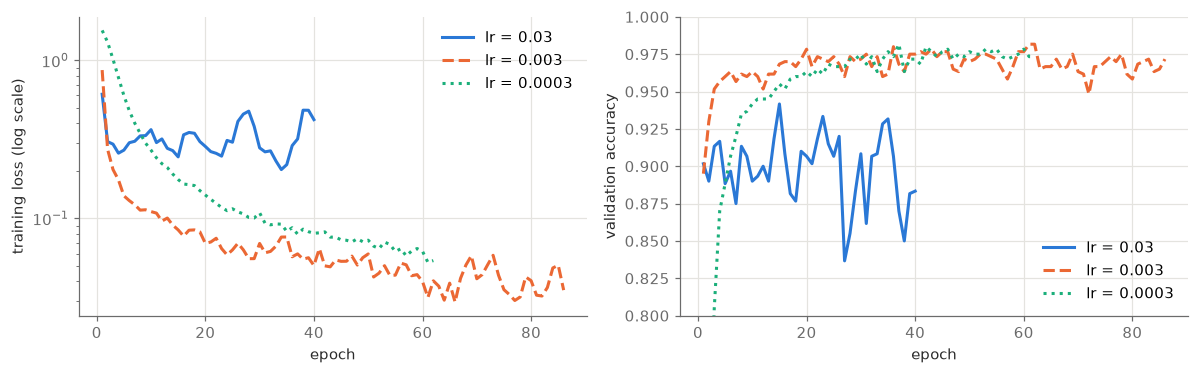

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for k, lr in enumerate([0.03, 0.003, 0.0003]):
    m, hist = train_mlp(lr=lr)
    ep = np.arange(1, len(hist["val_acc"]) + 1)
    axes[0].plot(ep, hist["train_loss"], color=plots.PALETTE[k], ls=plots.LINESTYLES[k], label=f"lr = {lr}")
    axes[1].plot(ep, hist["val_acc"], color=plots.PALETTE[k], ls=plots.LINESTYLES[k], label=f"lr = {lr}")
    print(f"lr = {lr:<7}: stopped after {len(ep):3d} epochs, best val acc {hist['best_val_acc']:.1%}, test acc {test_acc(m):.1%}")
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training loss (log scale)"); axes[0].legend()
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("validation accuracy"); axes[1].set_ylim(0.8, 1.0); axes[1].legend()
fig.tight_layout(); plt.show()

**Results and explanation.** Recall the update rule: $w \leftarrow w - \text{lr} \times \text{gradient}$. The learning rate is the size of each step downhill.

* **lr = 0.03 (10x too large).** The training loss drops fast at first but then stalls at a much *higher* level than with the default, and the validation accuracy jumps around and stays lower (best validation 94.2%, test 91.7% in our run). The steps are so large that the weights keep *overshooting* the bottom of the valley: like trying to stop at the lowest point of a bowl while taking giant strides. Early stopping ends the run after only 40 epochs because the noisy validation accuracy no longer improves.
* **lr = 0.003 (default).** Fast and steady progress; the best result (97.2% test).
* **lr = 0.0003 (10x too small).** The loss goes down smoothly but slowly: every step is tiny. In our run it still reached a good result (96.8% test) because Adam and early stopping give it enough epochs. With a fixed, small epoch budget it would have ended clearly undertrained.

**Takeaway.** The learning rate is the single most important training setting. Too large: unstable training, worse final result. Too small: slow training (and wasted compute). Typical practice is to try values a factor ~3-10 apart and pick the best on the *validation* set. That's also why later notebooks use a *smaller* learning rate (1e-3 or 5e-4) for **fine-tuning**: the network is already good, and we only want small corrections.

### Exercise 1.4 No augmentation
> Train with `augment=False`. Does test accuracy change? Why could the effect on the *real board* be bigger than on this test set?

**Approach.** First the straightforward comparison on the test set. Then a second experiment that answers the "why" question: we take the test gestures and **shift them in time**, as if the trigger on the board fired earlier or later than in the training data, and measure how both models cope.

test accuracy: with augmentation 97.2%, without 95.7%

shift -10 readings (-0.20 s): with 86.8%, without 63.0%
shift  -8 readings (-0.16 s): with 93.2%, without 72.7%
shift  -6 readings (-0.12 s): with 95.3%, without 81.3%
shift  -4 readings (-0.08 s): with 96.5%, without 89.3%
shift  -2 readings (-0.04 s): with 96.7%, without 93.3%
shift  +0 readings (+0.00 s): with 97.2%, without 95.7%
shift  +2 readings (+0.04 s): with 97.0%, without 94.7%
shift  +4 readings (+0.08 s): with 96.3%, without 90.8%
shift  +6 readings (+0.12 s): with 95.5%, without 86.2%
shift  +8 readings (+0.16 s): with 92.0%, without 78.3%
shift +10 readings (+0.20 s): with 87.3%, without 70.5%


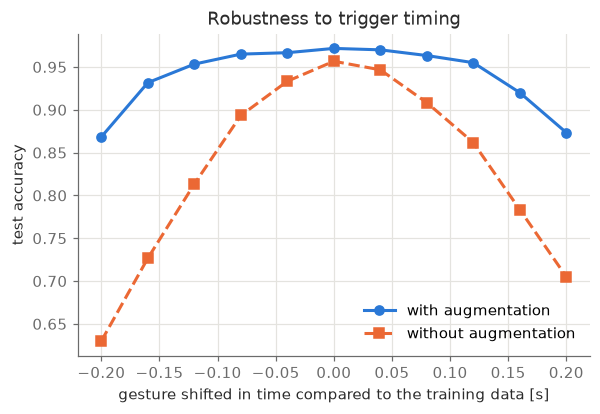

In [5]:
no_aug, _ = train_mlp(augment=False)
print(f"test accuracy: with augmentation {base_acc:.1%}, without {test_acc(no_aug):.1%}\n")

def shift_windows(raw, k):
    """Shift every window k readings later (k > 0) or earlier (k < 0), repeating the edge values."""
    idx = np.clip(np.arange(C.WINDOW_SAMPLES) - k, 0, C.WINDOW_SAMPLES - 1)
    return raw[:, idx, :]

shifts = list(range(-10, 11, 2))
curves = {"with augmentation": [], "without augmentation": []}
for k in shifts:
    Xs = data.normalize(shift_windows(data.raw_test, k))
    curves["with augmentation"].append(accuracy(baseline, Xs, data.y_test))
    curves["without augmentation"].append(accuracy(no_aug, Xs, data.y_test))
    print(f"shift {k:+3d} readings ({k / C.SAMPLE_RATE_HZ:+.2f} s): with {curves['with augmentation'][-1]:.1%}, "
          f"without {curves['without augmentation'][-1]:.1%}")
ax = plots.plot_curves([k / C.SAMPLE_RATE_HZ for k in shifts], curves,
                       xlabel="gesture shifted in time compared to the training data [s]",
                       title="Robustness to trigger timing")
plt.show()

**Results.** On the normal test set the difference is modest: 97.2% with augmentation vs 95.7% without, only slightly more than the ±1 point noise. If you only looked at this number, you might conclude augmentation hardly matters.

The shifted test sets tell a different story. When the gestures are shifted by 0.2 s (10 readings), the model trained **without** augmentation drops to 63-70%, while the model **with** augmentation still gets 87%. Even a shift of 0.08 s (4 readings) costs the un-augmented model 5-6 points, and the augmented model less than 1.

**Why the board can differ from the test set.** The test set comes from the *same* simulator, with the *same* distribution of trigger timings, speeds and grips as the training set. The model was never tested on anything really new. On the real board:
* the trigger fires at a slightly different moment of the movement, depending on how briskly you start;
* you perform gestures faster or slower than the simulated people;
* your board's axes, your grip and your sensor noise differ from the simulation.

All of these are **distribution shifts**: the data at deployment differs from the data at training. A test set drawn from the training distribution cannot reveal how robust a model is to them. Augmentation makes the model robust to *one* of these shifts (timing) for free.

**Takeaway.** A good test-set score is necessary but not sufficient. Ask "what will be different in the real world?" and test for it, as we did here with the shifted windows. That's also why notebook 05 ends with testing on the real board, and why recording your own data helps so much.

### Exercise 1.5 Seeds
> Train the baseline 3 times with `set_seed(0)`, `set_seed(1)`, `set_seed(2)` before creating the model (and `seed=` in `train`). How much does the test accuracy vary? Does this match the "±1 point" rule of thumb?

**Approach.** The seed controls all the randomness: the initial weights, the order of the mini-batches and the random time shifts of the augmentation. Different seeds → different, equally valid, training runs. We compare their test accuracies, and compare the spread with the statistical uncertainty of a 600-example test set.

In [6]:
accs = []
for s in [0, 1, 2]:
    m, _ = train_mlp(seed=s)
    accs.append(test_acc(m))
    print(f"seed {s}: {accs[-1]:.1%}")
print(f"mean {np.mean(accs):.1%}, standard deviation {np.std(accs):.1%}, range {min(accs):.1%} - {max(accs):.1%}")
p, n = np.mean(accs), len(data.y_test)
print(f"statistical uncertainty of one test-set measurement: sqrt(p(1-p)/n) = {np.sqrt(p * (1 - p) / n):.2%}")

seed 0: 97.2%


seed 1: 94.7%


seed 2: 95.5%
mean 95.8%, standard deviation 1.0%, range 94.7% - 97.2%
statistical uncertainty of one test-set measurement: sqrt(p(1-p)/n) = 0.82%


**Results.** In our run: 97.2%, 94.7% and 95.5%, so a mean of 95.8%, a standard deviation of 1.0 point and a range of 2.5 points. Yes, this matches (even slightly exceeds) the "±1 point" rule of thumb.

There are **two independent sources of variation**:

1. **The training run.** Different initial weights and batch orders lead to different final networks. Each one is a valid solution, but they make different mistakes on the borderline examples.
2. **The test set.** 600 examples is a finite sample. With an accuracy of $p \approx 0.96$, the standard error of the measured accuracy is $\sqrt{p(1-p)/n} = \sqrt{0.96 \cdot 0.04 / 600} \approx 0.8$ points. Even a *perfectly fixed* model would score ±0.8 points differently on another 600 test gestures.

A side note on reproducibility: on one computer with the same library versions, the same seed gives exactly the same model every time (seed 0 here reproduces the 97.2% of the baseline at the top). But on another computer, or with another PyTorch version, the maths libraries may add numbers in a slightly different order. That changes the last digits of some floats, and those tiny differences grow during training, so your seed-0 result may well differ by a point from ours. One more reason not to trust single runs.

**Takeaway.** Treat a single accuracy number as "± 1 point". To compare two methods properly: (1) use several seeds and compare the *means*, (2) look at the spread, and (3) only believe differences clearly larger than that spread. Notebooks 04 and 05 do exactly this.

---
# Part 02 · Quantization

### Exercise 2.1 ⭐ By hand
> Quantize the weights `[0.9, -0.3, 0.02, -1.8]` to 4 bits (symmetric, $q \in [-7, 7]$) on paper. What are $s$, the $q$'s, the dequantized values and the largest error? Check with code.

**By hand.**

1. **Scale.** Symmetric quantization maps the largest absolute value onto the largest integer: $s = \max|w| / 7 = 1.8 / 7 = 0.25714$.
2. **Divide by the scale:** $w / s = [3.5,\ -1.1667,\ 0.0778,\ -7.0]$.
3. **Round** to the nearest integer: $q = [\,?,\ -1,\ 0,\ -7]$. The first value is **exactly halfway** between 3 and 4: a *tie*. More on that below.
4. **Dequantize** $\hat w = s \cdot q$: $[\,0.7714 \text{ or } 1.0286,\ -0.2571,\ 0.0,\ -1.8]$.
5. **Errors** $\hat w - w$: $[\mp 0.1286,\ +0.0429,\ -0.02,\ 0.0]$.

The **largest error is 0.1286 = s/2**, exactly the theoretical maximum rounding error, because 0.9 sits precisely between two marks of the ruler. The value $-1.8$ is represented exactly (it defines the scale), and $0.02$ is rounded to 0: at 4 bits, small weights simply vanish (a 100% relative error, but only 0.02 in absolute terms).

In [7]:
w = torch.tensor([0.9, -0.3, 0.02, -1.8])
s = w.abs().max() / 7
q = torch.round(w / s).clamp(-7, 7)
print(f"s = {s.item():.5f}")
print("w / s       =", [round(v, 4) for v in (w / s).tolist()])
print("q           =", q.int().tolist())
print("dequantized =", [round(v, 4) for v in (q * s).tolist()])
print("error       =", [round(v, 4) for v in (q * s - w).tolist()], f"  max |error| = {(q * s - w).abs().max():.4f}, s/2 = {s / 2:.4f}")

w64 = torch.tensor([0.9, -0.3, 0.02, -1.8], dtype=torch.float64)    # the decimal numbers stored in float64
s64 = w64.abs().max() / 7
print("\nsame computation in float64: w / s =", [round(v, 17) for v in (w64 / s64).tolist()[:1]], "-> q =", torch.round(w64 / s64).int().tolist())

s = 0.25714
w / s       = [3.5, -1.1667, 0.0778, -7.0]
q           = [4, -1, 0, -7]
dequantized = [1.0286, -0.2571, 0.0, -1.8]
error       = [0.1286, 0.0429, -0.02, 0.0]   max |error| = 0.1286, s/2 = 0.1286

same computation in float64: w / s = [3.4999999999999996] -> q = [3, -1, 0, -7]


**The tie, explained.** On paper $0.9 / (1.8/7) = 3.5$ exactly. What the computer does depends on tiny rounding details:
* In **float32**, $0.9/s$ happens to come out as exactly 3.5. `torch.round` uses "round half to even" (banker's rounding: ties go to the even neighbour), so 3.5 → **4**.
* In **float64**, $0.9$ and $1.8/7$ are stored slightly differently, the quotient becomes 3.4999999999999996, and it rounds to **3**.

Both answers are correct quantizations: either way the error is $s/2$. Ties are exactly why the course's C++ code and its Python twin (`int8_forward`) carefully use the *same* float32 operations and the *same* rounding rule (`roundf`: half away from zero). Otherwise the board and Python would disagree on rare tie cases, and the self-test would not be bit-exact.

**Takeaway.** Maximum rounding error = $s/2$; with $b$ bits the scale is $\max|w|/(2^{b-1}-1)$, so every bit you remove doubles the error. And small values relative to the largest value in the group are the first to disappear.

### Exercise 2.2 ⭐ Outliers
> Take a copy of the baseline and set *one* weight of layer 0 to 20.0. Compare per-tensor vs per-channel 4-bit accuracy (`quantize_weights`). Explain the result with the "ruler" picture.

**Approach.** We reuse `quantize_weights` from notebook 02, insert the outlier, and measure: the float accuracy with the outlier (to see the effect of the outlier itself), and per-tensor vs per-channel 4-bit accuracy, with and without the outlier. We also count how many layer-0 weights become exactly 0 after rounding. That's the key to the explanation.

In [8]:
def quantize_weights(model, bits=8, per_channel=True):
    """Copy of `model` with weights rounded to `bits`-bit integers and back (from notebook 02)."""
    qmax = 2 ** (bits - 1) - 1
    m = copy.deepcopy(model)
    with torch.no_grad():
        for layer in m.layers:
            w = layer.weight
            max_abs = w.abs().amax(dim=1, keepdim=True) if per_channel else w.abs().max()
            s = max_abs / qmax
            layer.weight.copy_(torch.clamp(torch.round(w / s), -qmax, qmax) * s)
    return m

outlier = copy.deepcopy(baseline)
with torch.no_grad():
    outlier.layers[0].weight[0, 0] = 20.0          # neuron 0, input 0
W0 = baseline.layers[0].weight.detach()
print(f"layer 0 weights: max |w| = {W0.abs().max():.3f}, 99% of |w| are below {W0.abs().quantile(0.99):.3f}\n")
print(f"float32, original     : {base_acc:.1%}")
print(f"float32, with outlier : {test_acc(outlier):.1%}")
for name, model in [("original", baseline), ("with outlier", outlier)]:
    for pc in [False, True]:
        qm = quantize_weights(model, 4, per_channel=pc)
        zero_frac = (qm.layers[0].weight == 0).float().mean()
        print(f"4-bit {'per-channel' if pc else 'per-tensor ':12s} {name:13s}: {test_acc(qm):.1%}   "
              f"(layer-0 weights rounded to 0: {zero_frac:.0%})")

layer 0 weights: max |w| = 0.750, 99% of |w| are below 0.380

float32, original     : 97.2%
float32, with outlier : 96.3%
4-bit per-tensor   original     : 97.2%   (layer-0 weights rounded to 0: 44%)
4-bit per-channel  original     : 96.8%   (layer-0 weights rounded to 0: 28%)
4-bit per-tensor   with outlier : 20.0%   (layer-0 weights rounded to 0: 100%)
4-bit per-channel  with outlier : 96.0%   (layer-0 weights rounded to 0: 29%)


**Results.**

| | per-tensor 4-bit | per-channel 4-bit |
|---|---|---|
| original weights | 97.2% | 96.8% |
| with one outlier of 20.0 | **20.0%** | **96.0%** |

(The float network *with* the outlier still scores 96.3%: the outlier only changes one of 64 neurons, so it is not the outlier itself that breaks the network.)

**The ruler picture.** 4 bits gives a ruler with marks at $-7s, \dots, -s, 0, s, \dots, 7s$. The ruler must reach the largest value it has to represent.

* **Per-tensor, one ruler for the whole layer.** The outlier forces $s = 20 / 7 = 2.86$. The marks closest to zero are now at ±2.86. Every *normal* weight of layer 0 has $|w| \le 0.75$, far below half a step (1.43), so **all of them round to 0**. Layer 0 is reduced to a single connection: every neuron except neuron 0 outputs just its bias, whatever the input. The network now outputs (almost) the same prediction for every gesture, which gives 20% accuracy = 1 in 5 = *chance level*.
* **Per-channel, one ruler per neuron.** Only neuron 0's ruler is stretched to 20. Its other 299 weights round to 0, so neuron 0 becomes useless. But the other 63 neurons have their own, fine rulers and are unaffected. The damage is limited to 1 neuron out of 64: 96.0%.

A side note on the first row: without outliers, per-tensor (97.2%) and per-channel (96.8%) are equally good. The difference is noise. Interesting detail: per-tensor 4-bit rounds 44% of the layer-0 weights to 0 and the network doesn't notice. That's a preview of notebook 03: many weights are unimportant.

**Takeaway.** Quantization quality is set by the *range* each scale has to cover. A single extreme value can destroy a whole tensor. This is why real systems use per-channel scales for weights, and why outliers are a well-known problem in quantizing large networks (for example in large language models, where a few huge activation values make per-tensor 8-bit quantization fail).

### Exercise 2.3 Activation bits
> Try `QuantMLP(..., act_bits=4)` with weights at 8 bits. Which is more sensitive, weights or activations?

**Approach.** A fair comparison lowers *only one* of the two bit widths at a time, to the same value: W8/A4 vs W4/A8, W8/A3 vs W3/A8, and W8/A2. For each we measure PTQ and QAT accuracy (as in notebook 02's bit-width experiment).

In [9]:
for wb, ab in [(8, 8), (8, 4), (4, 8), (8, 3), (3, 8), (8, 2)]:
    q = QuantMLP(copy.deepcopy(baseline), weight_bits=wb, act_bits=ab)
    q.calibrate(data.X_train)
    ptq = test_acc(q)
    train(q, data, lr=5e-4, epochs=30, patience=10, augment=True, verbose=False)
    print(f"weights {wb} bits, activations {ab} bits:  PTQ {ptq:.1%}   QAT {test_acc(q):.1%}")

weights 8 bits, activations 8 bits:  PTQ 97.0%   QAT 97.0%


weights 8 bits, activations 4 bits:  PTQ 93.0%   QAT 96.2%


weights 4 bits, activations 8 bits:  PTQ 96.7%   QAT 97.2%


weights 8 bits, activations 3 bits:  PTQ 79.8%   QAT 93.3%


weights 3 bits, activations 8 bits:  PTQ 96.2%   QAT 97.5%


weights 8 bits, activations 2 bits:  PTQ 31.2%   QAT 68.8%


**Results.**

| bits lowered to | weights only (W*b*/A8): PTQ | weights only: QAT | activations only (W8/A*b*): PTQ | activations only: QAT |
|---|---|---|---|---|
| 4 | 96.7% | 97.2% | 93.0% | 96.2% |
| 3 | 96.2% | 97.5% | 79.8% | 93.3% |
| 2 | ~60% (notebook 02) | ~97% (notebook 02) | 31.2% | 68.8% |

(For reference: float32 97.2%, W8/A8 97.0%.)

**Activations are clearly more sensitive.** At 4 and 3 bits, quantizing the weights costs about one point at most, while quantizing the activations to the same number of bits costs 4 and 17 points with PTQ. QAT recovers most of the loss for 4-bit activations (96.2%), part of it at 3 bits (93.3%) and little at 2 bits (68.8%), while even 2-bit *weights* were fully recovered by QAT in notebook 02.

**Why?**
1. **One scale for everything.** Weights have one scale *per neuron* (per-channel). Activations have **one scale per layer**, shared by all neurons and *all inputs the board will ever see*. The scale must cover the largest activation ever observed (here up to ~41 after hidden layer 1, see exercise 2.4). With 4 bits that ruler has only 15 steps of $41/15 \approx 2.7$, while most activations are much smaller than one step. They get rounded to 0 or to a single step.
2. **The input is quantized too.** The 300 sensor features are themselves activations (point 0). With 4 bits each reading has only 16 possible values. That is a coarse picture of the gesture.
3. **Errors are fresh every time.** Weight errors are fixed: they are the same for every input, so the rest of the network (and QAT) can learn to compensate for them. Activation errors depend on the input and appear anew at every layer, adding up as they flow through the network.

**Takeaway.** In practice weights are pushed to low bit widths (4 bits is common, sometimes less), while activations are usually kept at 8 bits ("W4A8"). Our board uses W8A8, the safe and standard choice.

### Exercise 2.4 Calibration data
> Calibrate the PTQ model on only the first 10 training examples instead of all. What happens to the ranges and the accuracy? Why?

**Approach.** Compare the ranges and accuracy of calibration on all training data vs 10 examples. To understand the result we also count how many test values fall *outside* the small ranges (and would be clipped), and then try more extreme calibration sets: different sizes, 10 examples of a *single* gesture, and finally data from a board that isn't moving at all.

In [10]:
full = QuantMLP(copy.deepcopy(baseline)); full.calibrate(data.X_train)
tiny = QuantMLP(copy.deepcopy(baseline)); tiny.calibrate(data.X_train[:10])
for k in range(len(full.act_lo)):
    name = "input" if k == 0 else f"hidden {k}"
    print(f"{name:9s} all data [{full.act_lo[k]:6.2f}, {full.act_hi[k]:6.2f}]   "
          f"10 examples [{tiny.act_lo[k]:6.2f}, {tiny.act_hi[k]:6.2f}]")
print(f"\naccuracy: calibrated on all data {test_acc(full):.1%}, on 10 examples {test_acc(tiny):.1%}")
with torch.no_grad():
    x = data.X_test
    h1 = torch.relu(baseline.layers[0](x))
print(f"test inputs outside the 10-example input range: {((x < tiny.act_lo[0]) | (x > tiny.act_hi[0])).float().mean():.2%}")
print(f"hidden-1 activations above the 10-example max: {(h1 > tiny.act_hi[1]).float().mean():.2%}\n")

for n in [10, 30, 100, 300, 1000]:
    q = QuantMLP(copy.deepcopy(baseline)); q.calibrate(data.X_train[:n])
    print(f"calibrated on the first {n:4d} examples: {test_acc(q):.1%}")
for c, g in enumerate(C.GESTURES):
    idx = (data.y_train == c).nonzero().flatten()[:10]
    q = QuantMLP(copy.deepcopy(baseline)); q.calibrate(data.X_train[idx])
    print(f"calibrated on 10 '{g}' examples only: input range [{q.act_lo[0]:.1f}, {q.act_hi[0]:.1f}] -> {test_acc(q):.1%}")

still_raw = np.tile(np.array([0, 0, 1, 0, 0, 0], dtype=np.float32), (10, C.WINDOW_SAMPLES, 1))
still_raw += np.random.default_rng(0).normal(0, 0.01, still_raw.shape).astype(np.float32)
q = QuantMLP(copy.deepcopy(baseline)); q.calibrate(data.normalize(still_raw))
print(f"calibrated on 10 windows of a board lying still: input range [{q.act_lo[0]:.2f}, {q.act_hi[0]:.2f}], "
      f"hidden-1 max {q.act_hi[1]:.2f} -> {test_acc(q):.1%}")

input     all data [-16.79,  13.82]   10 examples [ -7.50,   8.18]
hidden 1  all data [  0.00,  40.97]   10 examples [  0.00,  25.83]
hidden 2  all data [  0.00,  49.01]   10 examples [  0.00,  19.73]

accuracy: calibrated on all data 97.0%, on 10 examples 97.0%
test inputs outside the 10-example input range: 0.06%
hidden-1 activations above the 10-example max: 0.08%

calibrated on the first   10 examples: 97.0%
calibrated on the first   30 examples: 97.2%
calibrated on the first  100 examples: 97.0%
calibrated on the first  300 examples: 97.0%
calibrated on the first 1000 examples: 97.2%
calibrated on 10 'punch' examples only: input range [-5.5, 4.6] -> 97.0%
calibrated on 10 'lift' examples only: input range [-5.9, 4.6] -> 97.0%
calibrated on 10 'wave' examples only: input range [-6.0, 5.4] -> 97.3%
calibrated on 10 'circle' examples only: input range [-6.4, 4.4] -> 97.2%
calibrated on 10 'twist' examples only: input range [-9.6, 8.2] -> 97.2%
calibrated on 10 windows of a board lyin

**Results.** With 10 examples, all ranges get **narrower**: the input range shrinks from about [-16.8, 13.8] to [-7.5, 8.2], and the hidden ranges to about half (41 → 26 and 49 → 20). But the accuracy doesn't change (97.0% in both cases), and it stays at ~97% for every calibration set size, and even when we calibrate on 10 examples of a single gesture! Only the board that lies still breaks the network (35.5%).

**Why so robust? The clipping-vs-resolution trade-off from notebook 02.**
* A min/max range is decided by the **most extreme value** in the calibration data. With all 2 800 examples × 300 features = 840 000 input values, a few rare extremes (a hard punch that saturates the accelerometer, a fast twist) stretch the range far beyond where almost all values lie.
* A narrower range **clips** those rare extremes: fewer than 0.1% of the test values fall outside the 10-example range. In exchange, it gives **all other values a finer ruler** (here ~2x finer).
* At 8 bits both effects are small: the ruler is already fine (256 steps), and clipping 0.1% of the values to the edge of the range barely changes the network's decision. So the accuracy hardly moves.

In fact, many quantization tools deliberately *don't* use min/max. They use, for example, the 99.99th percentile, or the range that minimises the quantization error, precisely because clipping a few outliers buys better resolution for everything else.

**When does calibration go wrong?** When the calibration data is **not representative** of what the board will see. The board lying still produces almost constant values: the input range shrinks to nearly nothing and every hidden activation is tiny. Then every real gesture is massively clipped, and the network is destroyed (35.5%, not far above the 20% of random guessing). The same could happen, less dramatically, if you calibrated on recordings from a different person, board or mounting.

**Takeaway.** Calibration needs *representative* data, not *much* data: a few hundred examples covering all situations is plenty. And with 8-bit activations, the simple min/max method is robust; at lower bit widths, choosing the range well matters much more.

### Exercise 2.5 Smaller models
> Repeat the bit-width experiment for a small `MLP(hidden=(16, 8))`. Do small networks tolerate quantization better or worse? Why could that be?

**Approach.** Run the PTQ/QAT bit-width sweep for the 16-8 network and the 64-32 baseline side by side, with the same settings. Compare each with its own float accuracy.

In [11]:
small_base, _ = train_mlp((16, 8))
small_acc = test_acc(small_base)
print(f"float32: 16-8 {small_acc:.1%},  64-32 {base_acc:.1%}")
for bits in [8, 4, 3, 2]:
    rows = []
    for name, model in [("64-32", baseline), ("16-8", small_base)]:
        q = QuantMLP(copy.deepcopy(model), weight_bits=bits); q.calibrate(data.X_train)
        ptq = test_acc(q)
        train(q, data, lr=5e-4, epochs=30, patience=10, augment=True, verbose=False)
        rows.append(f"{name}: PTQ {ptq:.1%}  QAT {test_acc(q):.1%}")
    print(f"{bits} bits | " + " | ".join(rows))

float32: 16-8 95.3%,  64-32 97.2%


8 bits | 64-32: PTQ 97.0%  QAT 97.0% | 16-8: PTQ 95.5%  QAT 95.5%


4 bits | 64-32: PTQ 96.7%  QAT 97.2% | 16-8: PTQ 95.2%  QAT 95.5%


3 bits | 64-32: PTQ 96.2%  QAT 97.5% | 16-8: PTQ 92.7%  QAT 95.8%


2 bits | 64-32: PTQ 60.2%  QAT 97.3% | 16-8: PTQ 66.2%  QAT 94.7%


**Results.**

| weight bits | 64-32: PTQ | 16-8: PTQ | 64-32: QAT | 16-8: QAT |
|---|---|---|---|---|
| float | 97.2% | 95.3% | | |
| 8 | 97.0% | 95.5% | 97.0% | 95.5% |
| 4 | 96.7% | 95.2% | 97.2% | 95.5% |
| 3 | 96.2% | **92.7%** | 97.5% | 95.8% |
| 2 | 60.2% | 66.2% | 97.3% | 94.7% |

**Small networks tolerate quantization somewhat worse.** At 8 and 4 bits both are fine. At 3 bits the small network loses 2.6 points with PTQ, the big one 1.0. At 2 bits both collapse with PTQ (no network is usable at 2 bits without QAT), and QAT brings the big network fully back to its float accuracy, while the small one ends ~0.6 points below its own. (These differences are close to the noise level. The 3-bit PTQ gap is the clearest signal.)

**Why?** **Redundancy.** In the 64-32 network, the information about a gesture is spread over many neurons. When rounding disturbs one neuron's output a little, the next layer sums over 64 (or 32) neurons, and the independent rounding errors partly *average out*. Many slightly-wrong neurons together still give the right answer. In the 16-8 network, every neuron carries a bigger share of the decision and the next layer sums over only 16 or 8 inputs, so the errors average out less and each one matters more. The same reasoning explains why the last, tiny layer suffered most from pruning in notebook 03.

**Takeaway.** Compression techniques interact: a network that is already small (by design or by pruning) has less redundancy left to absorb quantization errors. That's one reason notebook 05 finishes with **QAT** (the network adapts to the rounding) instead of plain PTQ, and why the order "prune first, quantize last" makes sense.

---
# Part 03 · Pruning

### Exercise 3.1 ⭐ Forget the mask
> Prune the baseline to 90% sparsity and fine-tune *without* `masks=`. Measure `sparsity_of(model)` after training. What happened, and why is that dangerous?

**Approach.** Prune to 90% with `prune_smallest` (from notebook 03), fine-tune once **with** and once **without** the masks, and measure the sparsity and the number of weights that are merely *small* (|w| < 0.01). Then we do what you would do when exporting a "pruned" model to a sparse format: apply the mask once more, after the un-masked fine-tuning.

In [12]:
def prune_smallest(model, sparsity):
    """Edge pruning with one global magnitude threshold (from notebook 03)."""
    m = copy.deepcopy(model)
    all_w = torch.cat([l.weight.detach().abs().flatten() for l in m.layers])
    threshold = torch.quantile(all_w, sparsity)
    masks = {}
    with torch.no_grad():
        for i, l in enumerate(m.layers):
            mask = (l.weight.abs() > threshold).float()
            l.weight.mul_(mask)
            masks[f"layers.{i}.weight"] = mask
    return m, masks

for use_mask in [True, False]:
    m, masks = prune_smallest(baseline, 0.9)
    before = sparsity_of(m)
    train(m, data, masks=masks if use_mask else None, lr=1e-3, epochs=40, patience=10, augment=True, verbose=False)
    W = torch.cat([l.weight.detach().flatten() for l in m.layers])
    print(f"{'with' if use_mask else 'WITHOUT'} masks: sparsity {before:.1%} -> {sparsity_of(m):.1%}, "
          f"weights with |w| < 0.01: {(W.abs() < 0.01).float().mean():.1%}, test accuracy {test_acc(m):.1%}")

with torch.no_grad():                           # "export": force the pruned weights to 0 again
    for i, l in enumerate(m.layers):
        l.weight.mul_(masks[f"layers.{i}.weight"])
print(f"un-masked fine-tuned model with the mask re-applied afterwards: test accuracy {test_acc(m):.1%}")

with masks: sparsity 90.0% -> 90.0%, weights with |w| < 0.01: 90.0%, test accuracy 97.5%


WITHOUT masks: sparsity 90.0% -> 0.0%, weights with |w| < 0.01: 26.3%, test accuracy 97.8%
un-masked fine-tuned model with the mask re-applied afterwards: test accuracy 82.8%


**What happened?** Without masks, the sparsity went from **90% to 0%**: every single pruned weight came back to life. Only about a quarter of the weights are even close to zero. The accuracy (97.8%) looks great, but that is the accuracy of a **dense** network again, with the full 84 KB of weights. The pruning was silently undone.

**Why do the weights grow back?** Setting a weight to zero doesn't make its *gradient* zero. As long as changing that weight would lower the loss, the optimizer (Adam) updates it like any other parameter. After one step the "pruned" weight is no longer zero, and after a few epochs it is back to a useful value. Weight decay pulls weights towards zero, but much too weakly to win against the gradient. The only way to keep pruned weights at zero is to re-apply the mask after every optimizer step, which is what `train(..., masks=masks)` does (`apply_masks` in `aiedge/training.py`).

**Why is that dangerous?** Two ways it can go wrong:
1. **You ship a model you think is pruned.** You report "90% sparse, 97% accurate", but the deployed model is just as big and slow as before. (This exact bug was in an earlier version of this course's code!)
2. **You notice it at export and apply the mask anyway.** The network was fine-tuned *relying on* the regrown weights. Re-applying the mask removes 90% of the weights that the network was using, and the accuracy collapses: **82.8%** in our run, instead of the 97.5% of the correctly masked fine-tuning.

**Takeaway.** Pruning = *mask* + fine-tuning *with the mask enforced*. Always **verify the sparsity of the final model** (`sparsity_of`) right before you export it. Check, don't assume.

### Exercise 3.2 ⭐ Global vs per-layer
> Use `magnitude_masks(baseline, 0.9, scope="layer")` (apply the masks by multiplying the weights, then fine-tune with `masks=`). Compare with the global version. Which is better, and why?

**Approach.** Build both mask sets with `magnitude_masks` (`scope="global"` and `scope="layer"`), apply them, fine-tune with the masks enforced, and look at *where* each one removes weights.

In [13]:
for scope in ["global", "layer"]:
    m = copy.deepcopy(baseline)
    masks = magnitude_masks(m, 0.9, scope=scope)
    with torch.no_grad():
        for n, p in m.named_parameters():
            if n in masks:
                p.mul_(masks[n])
    per_layer = [f"{1 - masks[f'layers.{i}.weight'].mean():.0%}" for i in range(3)]
    kept_last = int(masks["layers.2.weight"].sum())
    oneshot = test_acc(m)
    train(m, data, masks=masks, lr=1e-3, epochs=40, patience=10, augment=True, verbose=False)
    print(f"{scope:6s}: removed per layer {per_layer}, last layer keeps {kept_last}/160 weights, "
          f"one-shot {oneshot:.1%}, fine-tuned {test_acc(m):.1%}")

global: removed per layer ['92%', '76%', '48%'], last layer keeps 84/160 weights, one-shot 73.0%, fine-tuned 97.5%


layer : removed per layer ['90%', '90%', '90%'], last layer keeps 16/160 weights, one-shot 31.8%, fine-tuned 93.5%


**Results.**

| | layer 0 (300→64) | layer 1 (64→32) | layer 2 (32→5) | one-shot | fine-tuned |
|---|---|---|---|---|---|
| global threshold | 92% removed | 76% removed | 48% removed (84 of 160 kept) | 73.0% | **97.5%** |
| per-layer 90% | 90% | 90% | 90% (16 of 160 kept) | 31.8% | 93.5% |

Both remove 90% of all weights in total, but **global pruning is much better**: 97.5% vs 93.5% after fine-tuning (and 73% vs 32% right after pruning).

**Why?** Layers are not equally redundant:
* **Layer 0** has 19 200 weights connecting 300 inputs. Neighbouring readings in time are very similar (the signal changes slowly at 50 Hz), so many inputs carry nearly the same information, and many weights are dispensable.
* **Layer 2**, the output layer, has only 160 weights: 32 per gesture. Each of them directly decides how much a hidden feature counts for a gesture. With per-layer pruning only 16 remain, about **3 weights per gesture** for the final decision. That bottleneck limits the accuracy no matter how much we fine-tune.

The global threshold compares all weights on the same scale (their magnitude) and automatically takes most of the weights from where there are many unimportant ones (layer 0) and spares the small, critical last layer.

**Takeaway.** Use a global criterion, or give each layer its own carefully chosen sparsity. A common rule of thumb in practice is to prune the first and last layers less (or not at all), because they are small and critical.

### Exercise 3.3 Gradual pruning
> Shrink the baseline from (64, 32) to (16, 8) in 4 steps (48/24, 32/16, 24/12, 16/8) with a short fine-tune (20 epochs) after each step. Is it better than one-shot pruning + fine-tuning?

**Approach.** Gradual: 4 × (prune a bit + 20 epochs of fine-tuning) = 80 epochs. To compare fairly we also give the one-shot version a full **80 epochs** (not just the 60 with early stopping of notebook 03), so both get the same training budget.

In [14]:
m = copy.deepcopy(baseline)
for h in [(48, 24), (32, 16), (24, 12), (16, 8)]:
    m = prune_neurons(m, data.X_train, h)
    train(m, data, lr=1e-3, epochs=20, patience=20, augment=True, verbose=False)
    print(f"gradual: pruned to {h} and fine-tuned -> {test_acc(m):.1%}")
gradual_acc = test_acc(m)

one = prune_neurons(baseline, data.X_train, (16, 8))
train(one, data, lr=1e-3, epochs=60, patience=15, augment=True, verbose=False)
one_80 = prune_neurons(baseline, data.X_train, (16, 8))
train(one_80, data, lr=1e-3, epochs=80, patience=80, augment=True, verbose=False)
print(f"\ngradual (4 x 20 epochs): {gradual_acc:.1%}")
print(f"one-shot + up to 60 epochs (as in notebook 03): {test_acc(one):.1%}")
print(f"one-shot + 80 epochs (same budget as gradual):  {test_acc(one_80):.1%}")

gradual: pruned to (48, 24) and fine-tuned -> 96.2%


gradual: pruned to (32, 16) and fine-tuned -> 96.7%


gradual: pruned to (24, 12) and fine-tuned -> 96.5%


gradual: pruned to (16, 8) and fine-tuned -> 94.7%



gradual (4 x 20 epochs): 94.7%
one-shot + up to 60 epochs (as in notebook 03): 95.5%
one-shot + 80 epochs (same budget as gradual):  95.5%


**Results.** Gradual 94.7%, one-shot 95.5% (both with 60 and with 80 epochs). **Gradual pruning is not better here**: if anything slightly worse, but a difference of 0.8 points is within the noise. Note also how the gradual path went: 96.2% → 96.7% → 96.5% → 94.7%. The network stayed near the baseline down to 24-12, and lost accuracy only in the last step, where it reached a size that simply can't do better (a 16-8 network trained from scratch also gets ~95%).

**Why doesn't gradual pruning help here?**
* The idea of gradual pruning is that each step removes only a little, so the network never "falls off a cliff" and can adapt step by step. That matters when a single big cut would destroy knowledge that fine-tuning cannot rebuild.
* Here, fine-tuning rebuilds *everything* anyway: a 16-8 network trained from scratch reaches the same ~95% (notebook 03). Our task and network are small and the training data plentiful, so even after a brutal one-shot cut (accuracy ~40%), 60 epochs are enough to reach the ceiling of a 16-8 network.
* Gradual pruning shines with **large networks, high compression ratios and limited data/compute for fine-tuning**: the situations where training the small network from scratch is hard. Gradual magnitude pruning (e.g. Zhu & Gupta, *To prune, or not to prune*, 2017) is standard for big models.

**Takeaway.** Compare methods at an **equal training budget**, otherwise the method with more epochs wins for the wrong reason. And a "better" method that doesn't beat a simple baseline on *your* problem isn't better for your problem.

### Exercise 3.4 Another importance score
> Change the score to only the L1 norm of the *incoming* weights of each neuron (`model.layers[l].weight.abs().sum(dim=1)`) and use `remove_neurons` with it. Does the choice of score matter after fine-tuning?

**Approach.** Write a pruning function with the new score (the sum of the absolute incoming weights of every neuron, one row of the weight matrix), and compare it with the course's score (mean |activation| × size of outgoing weights) at three target sizes, both one-shot and after fine-tuning. We also check how many neurons both scores agree on.

In [15]:
def prune_by_incoming_l1(model, new_hidden):
    """Keep the neurons whose incoming weights have the largest L1 norm."""
    keep = [model.layers[l].weight.abs().sum(dim=1).argsort(descending=True)[:n]
            for l, n in enumerate(new_hidden)]
    return remove_neurons(model, keep)

for h in [(24, 12), (16, 8), (8, 4)]:
    res = []
    for name, make in [("activation x outgoing", lambda: prune_neurons(baseline, data.X_train, h)),
                       ("incoming L1", lambda: prune_by_incoming_l1(baseline, h))]:
        m = make(); a0 = test_acc(m)
        train(m, data, lr=1e-3, epochs=60, patience=15, augment=True, verbose=False)
        res.append(f"{name}: one-shot {a0:.1%} -> fine-tuned {test_acc(m):.1%}")
    print(f"{str(h):8s} " + " | ".join(res))

act_scores = neuron_importance(baseline, data.X_train)
l1 = baseline.layers[0].weight.abs().sum(dim=1)
overlap = len(set(act_scores[0].argsort(descending=True)[:24].tolist()) & set(l1.argsort(descending=True)[:24].tolist()))
print(f"\nhidden layer 1: {overlap} of the 24 neurons kept are chosen by both scores")

(24, 12) activation x outgoing: one-shot 52.0% -> fine-tuned 96.5% | incoming L1: one-shot 58.5% -> fine-tuned 96.2%


(16, 8)  activation x outgoing: one-shot 39.3% -> fine-tuned 95.5% | incoming L1: one-shot 44.5% -> fine-tuned 95.8%


(8, 4)   activation x outgoing: one-shot 31.3% -> fine-tuned 94.5% | incoming L1: one-shot 20.7% -> fine-tuned 94.5%

hidden layer 1: 15 of the 24 neurons kept are chosen by both scores


**Results.**

| target | activation × outgoing: one-shot → fine-tuned | incoming L1: one-shot → fine-tuned |
|---|---|---|
| 24-12 | 52.0% → 96.5% | 58.5% → 96.2% |
| 16-8 | 39.3% → 95.5% | 44.5% → 95.8% |
| 8-4 | 31.3% → 94.5% | 20.7% → 94.5% |

**Right after pruning (one-shot), the score matters**: differences of 5-10 points, and the simple incoming-L1 score even wins twice (but loses clearly at 8-4). The two scores agree on only 15 of the 24 neurons they keep, so they really select different networks.

**After fine-tuning, the score doesn't matter**: the differences shrink to 0-0.3 points, which is noise.

**Why?**
* *One-shot* accuracy measures how much of the original function survives the cut. That depends on which neurons were kept, so a better score gives a better one-shot result. Which score is "better" is not obvious. "Incoming L1" ignores whether a neuron is ever active on real data and whether the next layer listens to it. "Activation × outgoing" takes both into account, but it scores every neuron *on its own*: the true effect of removing a neuron also depends on the other neurons (two neurons doing the same job each look important, but you could remove one of them). Both are approximations.
* *Fine-tuning* retrains all remaining weights. For a network this small and this much data, it can reach nearly the best a 24-12 (or 16-8) network can do, whatever the starting point. This matches notebook 03's finding that training from scratch is about as good. What determines the final accuracy is mainly the **architecture** (how many neurons), not which neurons were kept. That's the central claim of Liu et al., *Rethinking the Value of Network Pruning* (2019).

**Takeaway.** Importance scores matter when you can't fine-tune much (big models, little data or compute). With enough fine-tuning, the *size* you prune to is the decision that counts. (Try a random selection of neurons as a bonus experiment: you will likely find it ends up about as good after fine-tuning!)

### Exercise 3.5 Think: removing inputs
> Our input layer has 300 inputs. Node pruning cannot remove inputs. Which inputs could you remove instead, and what would that mean physically (hint: channels and time steps)?

**Thinking it through.** The 300 inputs are 50 time steps × 6 channels. The input layer holds 89% of the baseline's weights (19 200 of 21 509), so reducing the inputs is the most effective way to shrink this model. There are three natural ways to remove inputs, each with a physical meaning:

| remove | physical meaning | consequence on the board |
|---|---|---|
| **channels** (e.g. the 3 gyroscope axes) | don't use the gyroscope at all | the gyroscope can be switched off; in MEMS IMUs the gyroscope typically draws much more current than the accelerometer (check your IMU's datasheet) |
| **time steps** (e.g. every second reading) | sample at 25 Hz instead of 50 Hz | read the IMU half as often: the CPU and sensor can sleep longer; less data to store |
| **the start or end of the window** | a shorter window | faster reaction (but the gesture may not fit any more) |

**Experiment.** Let's measure the first two. `select_inputs` builds a dataset from a subset of channels and/or every `every`-th time step (normalising with the same per-channel statistics). Note: we train **without augmentation** for all rows here, because the time-shift augmentation assumes the 50 × 6 layout. That's why the "baseline" row is slightly different from the usual baseline.

In [16]:
def select_inputs(d, channels=range(6), every=1):
    """New dataset with only some channels and/or only every `every`-th time step."""
    ch = list(channels)
    def pick(raw):
        sub = raw[:, ::every, :][:, :, ch]
        z = (sub - d.channel_mean[ch]) / d.channel_std[ch]
        return torch.from_numpy(z.reshape(len(sub), -1).astype(np.float32))
    return GestureData(pick(d.raw_train), d.y_train, pick(d.raw_val), d.y_val, pick(d.raw_test), d.y_test,
                       d.channel_mean[ch], d.channel_std[ch], raw_train=d.raw_train, raw_val=d.raw_val,
                       raw_test=d.raw_test, source=d.source)

variants = {
    "all 6 channels, 50 Hz (baseline)": dict(),
    "accelerometer only": dict(channels=[0, 1, 2]),
    "gyroscope only": dict(channels=[3, 4, 5]),
    "all channels, 25 Hz": dict(every=2),
    "all channels, 12.5 Hz": dict(every=4),
    "accelerometer only, 25 Hz": dict(channels=[0, 1, 2], every=2),
}
for name, kw in variants.items():
    d = select_inputs(data, **kw)
    m, _ = train_mlp(train_data=d, augment=False)
    print(f"{name:34s} inputs {d.X_train.shape[1]:3d}  params {count_params(m):6,}  MACs {count_macs(m):6,}  test {test_acc(m, d):.1%}")

all 6 channels, 50 Hz (baseline)   inputs 300  params 21,509  MACs 21,408  test 95.7%


accelerometer only                 inputs 150  params 11,909  MACs 11,808  test 93.2%


gyroscope only                     inputs 150  params 11,909  MACs 11,808  test 92.7%


all channels, 25 Hz                inputs 150  params 11,909  MACs 11,808  test 96.0%


all channels, 12.5 Hz              inputs  78  params  7,301  MACs  7,200  test 95.5%


accelerometer only, 25 Hz          inputs  75  params  7,109  MACs  7,008  test 89.2%


**Results.**

| inputs | number of inputs | parameters | test accuracy |
|---|---|---|---|
| all channels, 50 Hz | 300 | 21 509 | 95.7% |
| accelerometer only | 150 | 11 909 | 93.2% |
| gyroscope only | 150 | 11 909 | 92.7% |
| **all channels, 25 Hz** | **150** | **11 909** | **96.0%** |
| all channels, 12.5 Hz | 78 | 7 301 | 95.5% |
| accelerometer only, 25 Hz | 75 | 7 109 | 89.2% |

**Interpretation.**
* **Lowering the sample rate is almost free.** At 25 Hz (half the inputs, 45% fewer parameters and MACs) the accuracy doesn't change; even 12.5 Hz (a quarter of the inputs) loses nothing significant. Hand gestures are slow movements: their signal contains hardly anything faster than a few Hz, so 50 readings per second describe each gesture with lots of redundancy. (Signal theory, the *Nyquist criterion*, says you need to sample at least twice the highest frequency in the signal.) That's the same redundancy that made layer 0 so easy to prune in exercise 3.2.
* **Both sensors are needed.** Dropping either sensor costs 2.5-3 points: some gestures are mainly visible in the accelerometer (punch, lift), others mainly in the gyroscope (twist). And combining *both* reductions (accelerometer only at 25 Hz) costs 6.5 points.

**What would it take to deploy this?** For a lower sample rate: change `SAMPLE_RATE_HZ` and `WINDOW_SAMPLES` in `aiedge/config.py` (e.g. 25 and 25), the matching defaults in `gesture_recorder.h`, re-record or re-generate the data, and retrain. The board then simply reads the IMU every 40 ms instead of 20 ms. (On a real board you would also want the IMU's own low-pass filter set so that fast vibrations don't sneak in between the samples: *aliasing*.) For dropping a sensor you would also have to change the sketch, which now reads 6 values.

**Takeaway.** Before compressing the *model*, look at the *input*: the most effective (and energy-saving) compression often comes from collecting less, but sufficient, data. In this model, halving the sample rate saves more than the whole node-pruning step of notebook 03 at the same accuracy. (See exercise 5.2 for how this could help reach the challenge.)

---
# Part 04 · Knowledge distillation

**Shared preparation.** Most exercises of part 04 use the "little data" setting of notebook 04's experiment 2. We prepare the training subsets with 20, 40 and 80 examples per gesture once, and train one ConvNet teacher on each. The helper `compare_students` trains a student with and without the teacher for three seeds and returns the means and spreads.

In [17]:
def compare_students(train_data, teacher, h, seeds=(0, 1, 2), **kd):
    """Mean ± std of test accuracy for student `h`, without and with `teacher`, over three seeds."""
    kd = {"temperature": 4.0, "alpha": 0.5, **kd}
    aug = kd.pop("augment", True)
    plain, dist = [], []
    for s in seeds:
        m, _ = train_mlp(h, seed=s, train_data=train_data, augment=aug); plain.append(test_acc(m))
        m, _ = train_mlp(h, seed=s, train_data=train_data, augment=aug, teacher=teacher, **kd); dist.append(test_acc(m))
    return np.mean(plain), np.std(plain), np.mean(dist), np.std(dist)

small_sets, small_teachers = {}, {}
for n in [20, 40, 80]:
    small_sets[n] = limit_training_data(data, n)
    set_seed(0); t = ConvNet(); train(t, small_sets[n], augment=True, verbose=False)
    small_teachers[n] = t.eval()
    print(f"ConvNet teacher trained on {n} examples per gesture: {test_acc(t):.1%}")

ConvNet teacher trained on 20 examples per gesture: 90.0%


ConvNet teacher trained on 40 examples per gesture: 92.2%


ConvNet teacher trained on 80 examples per gesture: 95.2%


### Exercise 4.1 ⭐ Temperature
> Using `limit_training_data(data, 20)` and a teacher trained on it, distil the 32-16 student with $T = 1, 2, 4, 8$ (keep $\alpha = 0.5$). Which works best? What happens at $T = 1$, and why?

**Approach.** Distil with each temperature (three seeds each) and compare with the student without a teacher. To explain the results we also measure what the teacher's soft targets look like at each temperature: the average probability of the top gesture and of the second gesture.

In [18]:
d20, t20 = small_sets[20], small_teachers[20]
p, ps, _, _ = compare_students(d20, t20, (32, 16))
print(f"no teacher: {p:.1%} ± {ps:.1%}")
for T in [1, 2, 4, 8]:
    _, _, k, ks = compare_students(d20, t20, (32, 16), temperature=T)
    print(f"T = {T}: distilled {k:.1%} ± {ks:.1%}")

with torch.no_grad():
    logits = t20(data.X_val)
print()
for T in [1, 2, 4, 8]:
    pT = torch.softmax(logits / T, dim=1).sort(dim=1, descending=True).values
    print(f"T = {T}: teacher's soft targets: top gesture {pT[:, 0].mean():.3f} on average, "
          f"2nd {pT[:, 1].mean():.3f}, 3rd {pT[:, 2].mean():.3f}")

no teacher: 85.3% ± 0.9%


T = 1: distilled 86.3% ± 0.9%


T = 2: distilled 87.9% ± 0.7%


T = 4: distilled 88.4% ± 0.7%


T = 8: distilled 87.2% ± 0.3%

T = 1: teacher's soft targets: top gesture 0.944 on average, 2nd 0.046, 3rd 0.009
T = 2: teacher's soft targets: top gesture 0.883 on average, 2nd 0.079, 3rd 0.028
T = 4: teacher's soft targets: top gesture 0.762 on average, 2nd 0.125, 3rd 0.066
T = 8: teacher's soft targets: top gesture 0.584 on average, 2nd 0.175, 3rd 0.114


**Results.**

| | no teacher | T = 1 | T = 2 | **T = 4** | T = 8 |
|---|---|---|---|---|---|
| student 32-16 | 85.3% | 86.3% | 87.9% | **88.4%** | 87.2% |
| teacher's average top probability | | 0.944 | 0.883 | 0.762 | 0.584 |
| teacher's average 2nd probability | | 0.046 | 0.079 | 0.125 | 0.175 |

**T = 4 works best** here (T = 2 is close). Every temperature beats training without a teacher.

**What happens at T = 1?** The softmax is not softened, and the teacher is usually very sure: on average 94% for its top gesture and less than 5% for the runner-up. The soft targets then look almost like ordinary one-hot labels, so the soft loss says nearly the same as the hard loss. The "dark knowledge" (which wrong gestures are *similar* to the right one) is hidden in tiny probabilities that hardly contribute to the loss. Distillation still helps a bit (+1 point), mostly because the teacher labels the *shifted* (augmented) inputs, but much less than at higher T.

**Why not T = 8?** As $T$ grows, all probabilities move towards $1/5 = 0.2$. At T = 8 the top gesture gets only 58% on average. The relative differences between gestures are still there, but the signal "this one is correct" gets weaker, and the student learns from targets that are less sharp. Between "too sharp" (T = 1) and "too flat" (T = 8) lies the sweet spot, typically $T \approx 2$-$5$ in the literature.

**Takeaway.** The temperature controls *how much* of the teacher's knowledge about similarities is visible to the student. Like the learning rate, it is a hyperparameter to tune on the validation set.

### Exercise 4.2 ⭐ α = 1
> What does `alpha=1.0` mean? Predict the result first, then check.

**Prediction.** The loss is $\alpha \cdot \text{CE} + (1-\alpha) T^2 \text{KL}$. With $\alpha = 1$ the soft (teacher) term is multiplied by **0**, so the loss is just the ordinary cross-entropy with the labels: the teacher is completely ignored. We therefore predict *exactly* the same result as training without a teacher, with the same seed.

In [19]:
plain, _ = train_mlp((32, 16), train_data=d20)
alpha1, _ = train_mlp((32, 16), train_data=d20, teacher=t20, alpha=1.0)
same = all(torch.equal(p1, p2) for p1, p2 in zip(plain.parameters(), alpha1.parameters()))
print(f"no teacher: {test_acc(plain):.2%}   alpha = 1: {test_acc(alpha1):.2%}   bit-identical weights: {same}")

no teacher: 85.33%   alpha = 1: 85.33%   bit-identical weights: True


**Result.** Both give 85.33%, and the weights are **bit-identical**: the prediction is confirmed.

A subtle detail makes this *exactly* equal, not just approximately: the teacher still runs on every batch (we compute its output, then multiply its loss by zero), but its forward pass uses **no random numbers** (it is in evaluation mode, so dropout is off). The random generator therefore produces the same batch order and the same augmentation shifts in both runs. If the teacher's forward pass consumed random numbers, the two runs would diverge (statistically equal, but not identical).

**Takeaway.** $\alpha$ slides between "learn only from the labels" ($\alpha = 1$) and "learn only from the teacher" ($\alpha = 0$). Checking such an extreme case, where you *know* what must happen, is an excellent way to test that your code does what you think.

### Exercise 4.3 A different teacher
> Use `MLP(hidden=(256, 128), dropout=0.3)` as the teacher instead of the ConvNet. Is it a better or worse teacher? Is the best *model* always the best *teacher*?

**Approach.** Train the big MLP teacher on the same small training sets (20 and 80 examples per gesture), and distil the 32-16 student from it and from the ConvNet, three seeds each.

In [20]:
for n in [20, 80]:
    set_seed(0); mlp_teacher = MLP(hidden=(256, 128), dropout=0.3)
    train(mlp_teacher, small_sets[n], augment=True, verbose=False); mlp_teacher.eval()
    p, ps, k_cnn, kcs = compare_students(small_sets[n], small_teachers[n], (32, 16))
    _, _, k_mlp, kms = compare_students(small_sets[n], mlp_teacher, (32, 16))
    print(f"{n} per gesture: teachers: ConvNet {test_acc(small_teachers[n]):.1%}, big MLP {test_acc(mlp_teacher):.1%}  |  "
          f"student: no teacher {p:.1%}, ConvNet-taught {k_cnn:.1%} ± {kcs:.1%}, MLP-taught {k_mlp:.1%} ± {kms:.1%}")

20 per gesture: teachers: ConvNet 90.0%, big MLP 86.5%  |  student: no teacher 85.3%, ConvNet-taught 88.4% ± 0.7%, MLP-taught 85.6% ± 0.9%


80 per gesture: teachers: ConvNet 95.2%, big MLP 93.3%  |  student: no teacher 93.2%, ConvNet-taught 93.4% ± 0.3%, MLP-taught 92.4% ± 0.8%


**Results.**

| examples per gesture | ConvNet teacher | big-MLP teacher | student, no teacher | ConvNet-taught | MLP-taught |
|---|---|---|---|---|---|
| 20 | 90.0% | 86.5% | 85.3% | **88.4%** | 85.6% |
| 80 | 95.2% | 93.3% | 93.2% | **93.4%** | 92.4% |

**The big MLP is a worse model and a much worse teacher.** It barely beats the student (86.5% vs 85.3%), and the student learns nothing from it (85.6%, within noise of no teacher). At 80 examples it even slightly *hurts* (92.4% vs 93.2%).

**Why?** A teacher can only teach what the student couldn't learn on its own. The big MLP has the **same inductive bias** as the student: it also sees 300 unrelated numbers and has no built-in idea of time. Trained on the same 100 examples, it learns roughly the same things the student would learn, and it overfits in similar ways. Its soft targets contain little new information, and its mistakes partly mislead the student. The ConvNet, with its built-in assumption that "a pattern means the same thing wherever it appears in time", generalises better from few examples and genuinely knows something the student doesn't.

**Is the best model always the best teacher?** Here the more accurate model (ConvNet) was also the better teacher, but **not in general**. Research has shown that a more accurate teacher can be a *worse* teacher: for example a very large, very confident teacher whose function is too complex for a small student to imitate (the *capacity gap*; Cho & Hariharan, *On the Efficacy of Knowledge Distillation*, 2019; Mirzadeh et al. 2020 proposed "teacher assistants" for this). What makes a good teacher is a mix of: (1) being better than the student, (2) knowing something *different* from what the student can learn by itself, and (3) having a function the student is able to imitate.

**Takeaway.** Pick a teacher that brings something new: a different architecture, more data, or more compute than the student could use. A bigger copy of the student trained on the same data teaches little.

### Exercise 4.4 A bad teacher
> Train a teacher for only 2 epochs (`epochs=2`) and distil from it. What happens to the student?

**Approach.** Train a ConvNet for just 2 epochs, distil the student from it ($\alpha = 0.5$, and also with $\alpha = 0.9$ to rely more on the labels), and look at the bad teacher's soft targets.

In [21]:
for n in [20, 80]:
    set_seed(0); bad = ConvNet(); train(bad, small_sets[n], epochs=2, augment=True, verbose=False); bad.eval()
    p, ps, k, ks = compare_students(small_sets[n], bad, (32, 16))
    _, _, k9, k9s = compare_students(small_sets[n], bad, (32, 16), alpha=0.9)
    with torch.no_grad():
        top4 = torch.softmax(bad(data.X_val) / 4.0, dim=1).max(dim=1).values.mean()
    print(f"{n} per gesture: bad teacher {test_acc(bad):.1%} (avg top probability at T=4: {top4:.2f})  |  "
          f"student: no teacher {p:.1%}, alpha=0.5 {k:.1%} ± {ks:.1%}, alpha=0.9 {k9:.1%} ± {k9s:.1%}")

20 per gesture: bad teacher 53.0% (avg top probability at T=4: 0.21)  |  student: no teacher 85.3%, alpha=0.5 86.1% ± 0.9%, alpha=0.9 85.6% ± 1.1%


80 per gesture: bad teacher 81.2% (avg top probability at T=4: 0.38)  |  student: no teacher 93.2%, alpha=0.5 92.7% ± 0.5%, alpha=0.9 92.8% ± 0.4%


**Results.**

| examples per gesture | bad teacher | student, no teacher | distilled, α = 0.5 | distilled, α = 0.9 |
|---|---|---|---|---|
| 20 | 53.0% | 85.3% | 86.1% | 85.6% |
| 80 | 81.2% | 93.2% | 92.7% | 92.8% |

**Surprisingly, the bad teacher hardly hurts.** A teacher that is wrong on half (or a fifth) of the examples changes the student's accuracy by less than one point: slightly up with 20 examples, slightly down with 80, both within the noise.

**Why so little damage?**
1. **The labels are still there.** With $\alpha = 0.5$, half of the loss is the ordinary cross-entropy with the *true* labels. The student is always pulled towards the right answers.
2. **The bad teacher is unsure, so its soft targets are almost uniform.** After 2 epochs its logits are small; at T = 4 its top probability averages only 0.21 (20 examples per gesture) or 0.38 (80), close to the 0.2 of a uniform guess. (The good teacher of exercise 4.1: 0.76.) Its soft loss then mostly says "don't be too sure about anything". That is very close to **label smoothing**, a well-known regularisation technique that replaces one-hot labels by slightly softened ones. It can even help a little when data is scarce (Yuan et al., *Revisiting Knowledge Distillation via Label Smoothing Regularization*, 2020, showed that part of KD's benefit is this effect).
3. With more data (80 per gesture) the regularisation is less needed, and the bad teacher's actual mistakes start to cost a little.

With $\alpha = 0.9$ (90% labels, 10% teacher) the student simply ends up near the no-teacher result: the teacher's influence is turned down.

**But don't conclude "teacher quality doesn't matter"!** Compare with exercise 4.1: the good teacher gave +3 points, the bad one +0.8. A *confidently wrong* teacher would be far more harmful than this unsure one: it would actively push the student towards wrong answers with sharp targets.

**Takeaway.** Always evaluate your teacher before distilling. If it isn't clearly better than the student, distillation won't help. Use a larger $\alpha$ (trust the labels more) when the teacher is weak.

### Exercise 4.5 No augmentation
> Repeat experiment 2 with `augment=False` for both students. Is the gain from distillation bigger or smaller? Why? (Hint: see "the teacher labels new inputs".)

**Approach.** For each amount of data, compare the gain from distillation with and without augmentation (three seeds each). The teachers are the same in both cases (they were trained with augmentation); only the students' training changes.

In [22]:
for n in [20, 40, 80]:
    p, _, k, _ = compare_students(small_sets[n], small_teachers[n], (32, 16))
    pn, _, kn, _ = compare_students(small_sets[n], small_teachers[n], (32, 16), augment=False)
    print(f"{n} per gesture | with augmentation: {p:.1%} -> {k:.1%} ({100 * (k - p):+.1f})"
          f" | without: {pn:.1%} -> {kn:.1%} ({100 * (kn - pn):+.1f})")

20 per gesture | with augmentation: 85.3% -> 88.4% (+3.1) | without: 73.8% -> 73.6% (-0.2)


40 per gesture | with augmentation: 91.0% -> 91.8% (+0.8) | without: 82.4% -> 87.4% (+4.9)


80 per gesture | with augmentation: 93.2% -> 93.4% (+0.2) | without: 87.8% -> 89.7% (+1.9)


**Results.**

| examples per gesture | with augmentation: no teacher → distilled | gain | without augmentation: no teacher → distilled | gain |
|---|---|---|---|---|
| 20 | 85.3% → 88.4% | **+3.1** | 73.8% → 73.6% | **-0.2** |
| 40 | 91.0% → 91.8% | +0.8 | 82.4% → 87.4% | **+4.9** |
| 80 | 93.2% → 93.4% | +0.2 | 87.8% → 89.7% | +1.9 |

The answer is **"it depends"**, and that is more interesting than a simple yes or no. Two effects work in opposite directions:

1. **The teacher can no longer label new inputs (gain gets smaller).** With augmentation, the student sees a freshly shifted version of every example in every epoch, and the teacher provides a target for *each* of these new inputs. That turns 100 recordings into an endless stream of teacher-labelled examples. Without augmentation, the teacher only ever comments on the *same* 100 fixed inputs, which the student can memorise anyway. With **20 examples per gesture** this effect dominates: the gain disappears completely (-0.2).
2. **There is more overfitting to fix (gain gets bigger).** Without augmentation, the students overfit badly: 73.8% instead of 85.3% at 20 examples. The teacher's soft targets act as a regulariser (smoother, less over-confident targets that also encode similarities between gestures). Where enough examples exist for this regularisation to work, at 40 and 80 per gesture, the gain becomes *bigger* than with augmentation (+4.9 and +1.9).

**The most important comparison is a different one:** at 20 examples, augmentation alone is worth **+11.5 points** (73.8% → 85.3%), far more than distillation ever gave. And the best result by far comes from **both together** (88.4%).

**Takeaway.** Distillation and augmentation are partly *substitutes* (both fight overfitting) and partly *partners* (the teacher is most useful when it can label new, augmented inputs). In practice: always start with good augmentation; distillation is the cherry on top.

### Exercise 4.6 Student size
> Repeat experiment 2 with a 16-8 and a 64-32 student. Does the gain from distillation depend on the student's size?

In [23]:
for h in [(64, 32), (32, 16), (16, 8)]:
    gains = []
    for n in [20, 40, 80]:
        p, _, k, _ = compare_students(small_sets[n], small_teachers[n], h)
        gains.append(f"{n}: {p:.1%} -> {k:.1%} ({100 * (k - p):+.1f})")
    print(f"student {str(h):9s} " + " | ".join(gains))

student (64, 32)  20: 86.0% -> 88.2% (+2.2) | 40: 91.2% -> 91.9% (+0.8) | 80: 92.7% -> 94.1% (+1.4)


student (32, 16)  20: 85.3% -> 88.4% (+3.1) | 40: 91.0% -> 91.8% (+0.8) | 80: 93.2% -> 93.4% (+0.2)


student (16, 8)   20: 82.4% -> 84.9% (+2.5) | 40: 88.7% -> 89.3% (+0.7) | 80: 91.1% -> 92.6% (+1.4)


**Results** (no teacher → distilled, gain in points):

| student | 20 per gesture | 40 per gesture | 80 per gesture |
|---|---|---|---|
| 64-32 | 86.0% → 88.2% (+2.2) | 91.2% → 91.9% (+0.8) | 92.7% → 94.1% (+1.4) |
| 32-16 | 85.3% → 88.4% (+3.1) | 91.0% → 91.8% (+0.8) | 93.2% → 93.4% (+0.2) |
| 16-8 | 82.4% → 84.9% (+2.5) | 88.7% → 89.3% (+0.7) | 91.1% → 92.6% (+1.4) |

**The gain depends much more on the amount of data than on the student's size.** In every column the three sizes gain about the same (the differences of ~1 point within a column, like +0.2 vs +1.4 at 80 examples, are within the noise of three seeds). Reading along the rows, the gain clearly shrinks as data grows: ~2-3 points at 20 examples, under 1 point at 40.

Why is there no capacity gap for the 16-8 student here, while notebook 04's experiment 1 hinted at one for tiny students? The teachers trained on little data are not that far ahead (90-95%), and even the 16-8 student has enough capacity to imitate them. A capacity gap appears when the teacher's function is much more complex than what the student can represent: a very strong teacher and a very small student (the 8-neuron student in notebook 04's experiment 1).

**Takeaway.** Distillation helps most when the *data* is the bottleneck, which is exactly the situation of a student recording a few dozen gestures. The size of the student matters less, as long as it isn't tiny compared with what the teacher knows.

---
# Part 05 · Deployment

**Shared preparation.** A teacher trained on the full data, the 3-seed baseline reference (as in notebook 05), and a `pipeline` function that reproduces notebook 05's distill → prune → quantize recipe. Each step can be switched off, which we need for the ablation (exercise 5.5).

In [24]:
set_seed(0)
teacher = ConvNet(); train(teacher, data, augment=True, verbose=False); teacher.eval()
base_runs = [test_acc(train_mlp(seed=s)[0]) for s in [0, 1, 2]]
ref = float(np.mean(base_runs))
print(f"teacher {test_acc(teacher):.1%}, baseline reference (3 seeds) {ref:.1%} -> challenge needs >= {ref - 0.01:.1%}")

def pipeline(train_data=None, final_hidden=(24, 12), kd=True, prune=True, quant=True, teacher=teacher, seed=0):
    """Notebook 05's recipe. Returns (test accuracy, model bytes, final model)."""
    d = train_data or data
    KD = dict(teacher=teacher, temperature=4.0, alpha=0.5) if kd else {}
    m, _ = train_mlp((64, 32), seed=seed, train_data=d, **KD)                 # (distilled) 64-32 student
    if prune:                                                                  # node pruning + fine-tuning
        m = prune_neurons(m, d.X_train, final_hidden)
        train(m, d, lr=1e-3, augment=True, seed=seed, verbose=False, **KD)
    if not quant:
        return test_acc(m), 4 * count_params(m), m
    q = QuantMLP(copy.deepcopy(m)); q.calibrate(d.X_train)                    # int8 QAT
    train(q, d, lr=5e-4, epochs=40, patience=10, augment=True, seed=seed, verbose=False, **KD)
    im = q.to_int8()
    return int8_accuracy(im, data.X_test, data.y_test), int8_model_bytes(im), q

teacher 98.0%, baseline reference (3 seeds) 95.8% -> challenge needs >= 94.8%


### Exercise 5.1 ⭐ Fill in the table in section 5, and answer the questions
> Upload the sketch with `MODEL_PRECISION 8` and `32`; fill in flash, RAM and inference time; answer the questions below the table.

This exercise needs the board, so the inference *times* must be measured by you. What we *can* do here: report the compiler's flash/RAM numbers (they don't depend on the board, only on the code), predict the timing in a well-founded way, and work out the answers.

**Measured compile results** (Arduino Mbed OS Nano Boards 4.6.0, the 24-12 model shipped with the course):

| | int8 | float32 | difference |
|---|---|---|---|
| sketch flash, Rev1 (LSM9DS1) | 107 608 B | 129 736 B | −22 128 B |
| sketch flash, Rev2 (BMI270) | 128 576 B | 150 704 B | −22 128 B |
| sketch RAM ("global variables"), Rev1 | 49 520 B | 48 784 B | **+736 B** |
| sketch RAM, Rev2 | 50 176 B | 49 448 B | +728 B |
| inference time | *measure* | *measure* | |

(Your numbers may differ by a few hundred bytes with another core version, and the flash difference changes if you deploy a different `FINAL_HIDDEN`.)

**Flash.** The model's parameters take 7 876 B (int8) vs 30 356 B (float32): an expected difference of 22 480 B. The measured difference, 22 128 B, is within 2% of that; the rest is the slightly different code of the two inference functions. But look at the totals: the **whole int8 sketch is ~108 KB, of which the model is only 7.9 KB (7%)**. The capture sketch, which has no model at all, is already 95 KB. Most of the flash goes to the Arduino core, the Mbed OS underneath, USB serial and the IMU library. (Rev2 is ~21 KB bigger than Rev1 because the BMI270 library includes the sensor's configuration file.)

**RAM: int8 uses slightly *more*.** Surprising? The weights are `const` and live in flash, so they don't count here. RAM holds the *working buffers*. The int8 path needs an int8 copy of the 300 inputs (300 B), an int16 buffer of "centred" inputs (600 B) and a small output buffer (24 B), about 924 B. The float path only needs two 24-float buffers (192 B), because it reads the 300 float features in place. 924 − 192 = 732 B ≈ the measured 736 B. Lesson: "int8 = 4x smaller" applies to the *weights*; for activations and buffers it depends on the implementation.

In [25]:
q_final = pipeline()[2]
macs = count_macs(q_final.mlp)
print(f"MACs per prediction: {macs:,}")
for cpm in [4, 8, 10]:
    print(f"  at {cpm:2d} cycles per MAC: {macs * cpm / 64:6.0f} us at 64 MHz")

MACs per prediction: 7,548
  at  4 cycles per MAC:    472 us at 64 MHz
  at  8 cycles per MAC:    944 us at 64 MHz
  at 10 cycles per MAC:   1179 us at 64 MHz


**Predicting the inference time from the machine code.** We can look at what the compiler actually produced for the inner loops (`arm-none-eabi-objdump -d` on the compiled sketch):

```
int8 inner loop (one MAC per iteration)           float32 inner loop (one MAC per iteration)
  cmp     r0, sl          ; i < n_in ?              cmp       sl, r8          ; i < n_in ?
  bge.n   <done>                                    bge.n     <done>
  ldrsb.w ip, [r6, r0]    ; load int8 weight        vldmia    r6!, {s13}      ; load float weight
  ldrh.w  lr, [fp, r0, lsl #1] ; load int16 input   vldmia    fp!, {s14}      ; load float input
  adds    r0, #1                                    add.w     sl, sl, #1
  smlabb  r3, lr, ip, r3  ; acc += w * x (DSP MAC)  vfma.f32  s15, s13, s14   ; acc += w * x (FPU)
  b.n     <loop>                                    b.n       <loop>
```

Both loops have **7 instructions per MAC**: two loads, one multiply-accumulate, and four instructions of loop overhead. On a Cortex-M4 loads take 1-2 cycles and a taken branch 2-3, so each iteration costs roughly **8-10 cycles**, for int8 *and* float. Our cost model's "4 cycles per MAC" was optimistic by about a factor of 2. (The compiler uses `-Os`, optimise for *size*, so it doesn't unroll the loop.) That predicts about **0.9-1.2 ms** per prediction for the 7 548 MACs, for both precisions.

The int8 version has **extra work outside the loop**: quantizing the 300 inputs costs a float division (`vdiv`, 14 cycles) and a call to the library function `roundf` for each one, roughly 300 × ~50 cycles ≈ 0.2-0.3 ms. **Our prediction: int8 will be about as fast as float32, or a bit slower.** Measure it and see!

**Answers to the questions of section 5.**
* *Is the flash difference what you expected?* Yes: ~22 KB, equal to the difference in parameter bytes. But the model is a small part of the total flash; most is the Arduino/Mbed core.
* *Is int8 faster on this chip?* Very likely not, with our simple C loop (see the prediction above). The Cortex-M4F has a hardware FPU, so a float multiply-add is as cheap as an integer one, and both loops are dominated by loads and loop overhead. int8 *can* be much faster with optimised kernels: the M4's `SMLAD` instruction does **two** 16-bit multiply-accumulates at once, and libraries like CMSIS-NN combine it with loop unrolling, typically giving several times the speed of a naive loop. On microcontrollers *without* an FPU (Cortex-M0/M3), int8 is dramatically faster than float, which is emulated in software. Here, int8's benefit is the **4x smaller weights**.
* *Cycles per MAC?* Compute $\text{cycles/MAC} = t_{\mu s} \times 64 / 7548$. Expect roughly 8-12 for float32 and somewhat more for int8 (because of the input quantization), versus the course's guess of 4. A good exercise in why you must measure: rules of thumb are a start, not an answer.
* *Energy?* The board needs **1 second** to record a gesture and **~1 ms** to classify it: inference is about 0.1% of the time! Even a 10x faster model would barely change the battery life. Moreover, the sketch's `loop()` *busy-waits* (it keeps asking "is it time for the next sample yet?"), so the CPU runs at full power all the time. The big energy savings are elsewhere: let the CPU **sleep** between samples (e.g. use the IMU's data-ready interrupt or its FIFO), **sample less often** (exercise 3.5: 25 Hz costs no accuracy), switch off unused sensors, LEDs and the USB serial port, and use the IMU's built-in low-power motion detection to wake the system only when the board moves. For this application, the model is already "small enough". In a vision or audio application, where inference runs continuously and takes milliseconds to seconds, the model's cost would dominate instead.

### Exercise 5.2 ⭐ Push the challenge
> What is the smallest `FINAL_HIDDEN` that still meets the "-1 point" rule? Can you get below 5 KB?

**Approach.** Run notebook 05's pipeline for decreasing sizes, with two seeds each (one run is too noisy to decide a challenge on), and compare with the baseline reference minus 1 point.

In [26]:
for h in [(32, 16), (24, 12), (16, 8), (12, 6), (8, 4), (6, 3)]:
    accs, nbytes = [], 0
    for s in [0, 1]:
        a, nbytes, _ = pipeline(final_hidden=h, seed=s); accs.append(a)
    verdict = "meets the -1 rule" if np.mean(accs) >= ref - 0.01 else "too inaccurate"
    print(f"{str(h):9s} {nbytes:6,} B ({nbytes / 1024:4.1f} KB)  accuracy {np.mean(accs):.1%} "
          f"(seeds: {', '.join(f'{a:.1%}' for a in accs)})  -> {verdict}")

(32, 16)  10,616 B (10.4 KB)  accuracy 95.8% (seeds: 95.2%, 96.5%)  -> meets the -1 rule


(24, 12)   7,876 B ( 7.7 KB)  accuracy 96.3% (seeds: 96.0%, 96.7%)  -> meets the -1 rule


(16, 8)    5,200 B ( 5.1 KB)  accuracy 94.9% (seeds: 95.5%, 94.3%)  -> meets the -1 rule


(12, 6)    3,886 B ( 3.8 KB)  accuracy 94.7% (seeds: 95.2%, 94.2%)  -> too inaccurate


(8, 4)     2,588 B ( 2.5 KB)  accuracy 94.7% (seeds: 95.2%, 94.2%)  -> too inaccurate


(6, 3)     1,945 B ( 1.9 KB)  accuracy 90.4% (seeds: 91.0%, 89.8%)  -> too inaccurate


**Results** (reference 95.8%, so at least 94.8% is needed):

| FINAL_HIDDEN | int8 bytes | accuracy (mean of 2 seeds) | challenge |
|---|---|---|---|
| 32-16 | 10 616 (10.4 KB) | 95.8% | ✅ accuracy, but > 10 KB |
| 24-12 | 7 876 (7.7 KB) | 96.3% | ✅ |
| **16-8** | **5 200 (5.1 KB)** | **94.9%** | ✅ (just) |
| 12-6 | 3 886 (3.8 KB) | 94.7% | ❌ by 0.1 point |
| 8-4 | 2 588 (2.5 KB) | 94.7% | ❌ by 0.1 point |
| 6-3 | 1 945 (1.9 KB) | 90.4% | ❌ |

**The smallest size that meets the rule is 16-8 at 5.1 KB**, just above 5 KB. 12-6 (3.8 KB) and even 8-4 (2.5 KB) miss by only 0.1 point, far less than the noise. Honestly, 16-8, 12-6 and 8-4 are statistically indistinguishable; with other seeds 12-6 or 8-4 might pass. Below 8-4 the accuracy collapses (6-3: 90.4%): the network no longer has enough neurons to separate five gestures.

**How to get below 5 KB with a safe margin?** Look at where the bytes go. In the 16-8 network, the first layer has 300 × 16 = 4 800 of the 4 968 weights. Making the hidden layers smaller is running out of steam; **shrinking the input is the lever** (exercise 3.5):
* At **25 Hz** (150 inputs) the first layer of a 16-8 network halves: 150 × 16 + 16 × 8 + 8 × 5 = 2 568 int8 weights + 29 neurons × 8 bytes (bias + multiplier) = **2 800 bytes ≈ 2.7 KB**, and exercise 3.5 showed 25 Hz costs no accuracy. Even a 24-12 network at 25 Hz would be ~4.3 KB.
* **4-bit weights** (notebook 02: QAT keeps the accuracy) would halve the weight bytes again, but need packing/unpacking code in `edge_nn.h`.

(We did not run the 25 Hz pipeline here: it needs the config, the augmentation and the sketch adapted to 25 readings per window. A nice project!)

**Takeaway.** When one technique saturates (here: removing neurons), look for another dimension to compress (the input, the bit width). And decide challenges on averages over several runs, not on a single lucky one.

### Exercise 5.3 Confidence threshold
> Change `CONFIDENCE_THRESHOLD` in the sketch (0.6 by default). What happens with random movements (not one of the 5 gestures) at 0.4 and at 0.9?

**Approach.** On the board: just try it. Here we simulate the same thing with the final int8 model (the exact integer arithmetic of the board, via `int8_forward`):
* **real gestures**: the test set;
* **random movements**: windows with a random tilt and smooth random accelerations and rotations (aimless hand movement, nothing like our 5 gestures);
* **mixed gestures**: two different test gestures averaged together. That's an in-between movement which is not really any gesture.

For each threshold we count how often the board would answer, and how often it says "not sure".

threshold | gestures answered acc. of answered | random motion rejected mixed gestures rejected
     0.40 |            100.0%            96.0% |                   0.0%                    0.6%
     0.50 |             99.7%            96.3% |                   1.2%                    2.1%
     0.60 |             97.5%            96.9% |                   5.0%                    4.6%
     0.70 |             95.5%            97.0% |                   8.2%                    9.5%
     0.80 |             93.2%            98.0% |                  12.7%                   14.5%
     0.90 |             88.8%            98.3% |                  19.3%                   20.9%
     0.95 |             85.5%            98.8% |                  26.2%                   26.7%


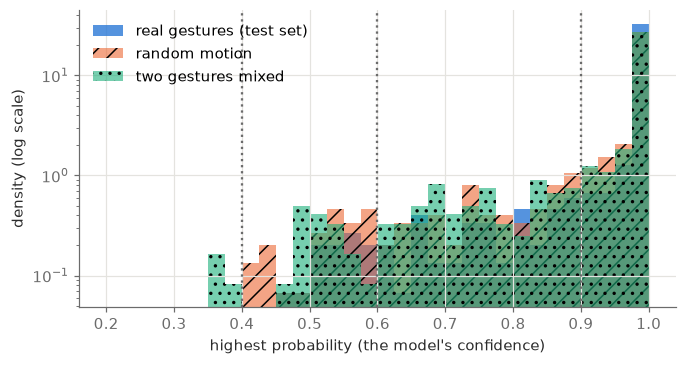

In [27]:
im = q_final.to_int8()
def probs_of(X):
    return torch.softmax(torch.from_numpy(int8_forward(im, X.numpy())), dim=1)

p_test = probs_of(data.X_test)
conf, pred = p_test.max(dim=1)
correct = pred == data.y_test

rng = np.random.default_rng(1)
def random_motion(n):
    """Windows of aimless movement: gravity at a random tilt + smooth random acceleration and rotation."""
    t = np.arange(C.WINDOW_SAMPLES)[:, None] / C.SAMPLE_RATE_HZ
    out = []
    for _ in range(n):
        g = rng.normal(size=3); g = g / np.linalg.norm(g) * 0.3 + np.array([0, 0, 1.0]); g /= np.linalg.norm(g)
        acc = np.tile(g, (C.WINDOW_SAMPLES, 1)); gyr = np.zeros((C.WINDOW_SAMPLES, 3))
        for _ in range(3):
            f, ph = rng.uniform(0.5, 4.0), rng.uniform(0, 2 * np.pi, 3)
            acc += rng.uniform(0, 0.8, 3) * np.sin(2 * np.pi * f * t + ph)
            gyr += rng.uniform(0, 150, 3) * np.sin(2 * np.pi * f * t + ph[::-1])
        out.append(np.concatenate([acc, gyr], axis=1))
    return np.array(out, dtype=np.float32)

X_rand = data.normalize(random_motion(600))
i, j = rng.integers(0, len(data.raw_test), 600), rng.integers(0, len(data.raw_test), 600)
keep = data.y_test.numpy()[i] != data.y_test.numpy()[j]
X_mix = data.normalize(0.5 * data.raw_test[i[keep]] + 0.5 * data.raw_test[j[keep]])
conf_rand = probs_of(X_rand).max(dim=1).values
conf_mix = probs_of(X_mix).max(dim=1).values

print(f"{'threshold':>9} | {'gestures answered':>17} {'acc. of answered':>16} | {'random motion rejected':>22} {'mixed gestures rejected':>23}")
for th in [0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]:
    ans = conf >= th
    print(f"{th:>9.2f} | {ans.float().mean():>17.1%} {correct[ans].float().mean():>16.1%} | "
          f"{(conf_rand < th).float().mean():>22.1%} {(conf_mix < th).float().mean():>23.1%}")

fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.linspace(0.2, 1.0, 33)
ax.hist(conf.numpy(), bins=bins, color=plots.PALETTE[0], alpha=0.8, label="real gestures (test set)", density=True)
ax.hist(conf_rand.numpy(), bins=bins, color=plots.PALETTE[1], alpha=0.6, label="random motion", density=True, hatch="//")
ax.hist(conf_mix.numpy(), bins=bins, color=plots.PALETTE[2], alpha=0.6, label="two gestures mixed", density=True, hatch="..")
for th in [0.4, 0.6, 0.9]:
    ax.axvline(th, color=plots.MUTED, ls=":", lw=1.5)
ax.set_xlabel("highest probability (the model's confidence)"); ax.set_ylabel("density (log scale)")
ax.set_yscale("log"); ax.legend(loc="upper left"); plt.show()

**Results.**

| threshold | real gestures answered | accuracy of the answered ones | random motion rejected | mixed gestures rejected |
|---|---|---|---|---|
| 0.4 | 100% | 96.0% | **0%** | 0.6% |
| 0.6 (default) | 97.5% | 96.9% | 5% | 4.6% |
| 0.9 | 88.8% | 98.3% | **19%** | 21% |

**At 0.4** the board practically never says "not sure": every random movement is reported as one of the five gestures. **At 0.9** it rejects about a fifth of the random movements, but **81% of them are still reported as a gesture**, while 11% of the *real* gestures are now ignored (the ones it does answer are more often right: 98.3%).

So raising the threshold trades **false alarms** (random motion reported as a gesture) for **misses** (real gestures ignored), like adjusting the sensitivity of a smoke detector. But no threshold separates real gestures from random motion well: the histogram shows that the model is *very* confident (> 0.9) about most random movements too.

**Why is the model so sure about movements it has never seen?** Because it has no way to say "none of these". The softmax always distributes 100% over the five known gestures, and the network was only ever trained to choose between them. For an input unlike anything in training (*out-of-distribution*), its output is essentially arbitrary, and it is often an arbitrary *confident* choice. Neural networks are notoriously over-confident on unfamiliar inputs.

**The real fix:** give the model the option to say no. Add a sixth class **"other"**, trained with recordings of non-gestures (random movements, walking with the board, picking it up, putting it down). Then "other" competes with the gestures on equal terms, and the threshold only handles the truly ambiguous cases. (With the capture sketch this is easy: record a few minutes of random movement as `other.csv` and add `"other"` to `GESTURES`.)

**Takeaway.** A confidence threshold is a cheap safety margin, not a detector of unknown inputs. If "none of the above" happens in practice, it must be part of the training data. (Our random motion is a simulation; check on the board whether your random movements behave the same!)

### Exercise 5.4 Without distillation
> Replace `**KD` by `augment=True, verbose=False` everywhere (no teacher). How much accuracy does the final int8 model lose with the synthetic data? And with your own recorded data?

**Approach.** Run the full pipeline with and without the teacher (three seeds each) on the full synthetic data, and on 40 and 20 examples per gesture as a stand-in for "your own recorded data" (the teachers come from part 04 and were trained on the same small sets).

In [28]:
for name, d, t in [("synthetic, full data", data, teacher),
                   ("40 recordings per gesture", small_sets[40], small_teachers[40]),
                   ("20 recordings per gesture", small_sets[20], small_teachers[20])]:
    with_kd = [pipeline(train_data=d, teacher=t, seed=s)[0] for s in [0, 1, 2]]
    without = [pipeline(train_data=d, kd=False, seed=s)[0] for s in [0, 1, 2]]
    print(f"{name:27s}: with teacher {np.mean(with_kd):.1%} ± {np.std(with_kd):.1%}, "
          f"without {np.mean(without):.1%} ± {np.std(without):.1%}  -> {100 * (np.mean(with_kd) - np.mean(without)):+.1f} points")

synthetic, full data       : with teacher 96.2% ± 0.4%, without 95.9% ± 0.2%  -> +0.2 points


40 recordings per gesture  : with teacher 90.9% ± 1.2%, without 90.1% ± 0.9%  -> +0.9 points


20 recordings per gesture  : with teacher 85.4% ± 1.2%, without 85.3% ± 0.6%  -> +0.1 points


**Results.**

| training data | final int8 model with teacher | without teacher | difference |
|---|---|---|---|
| full synthetic (560 per gesture) | 96.2% | 95.9% | +0.2 |
| 40 per gesture | 90.9% | 90.1% | +0.9 |
| 20 per gesture | 85.4% | 85.3% | +0.1 |

With the full synthetic data, leaving out distillation costs **nothing measurable**, as expected from notebook 04. With 40 examples per gesture it costs about a point. But with 20 examples per gesture, where notebook 04 showed distillation's *biggest* gain (+3 points), the whole pipeline gains **nothing**. Why? Let's look at every stage of the pipeline separately:

In [29]:
d20, t20 = small_sets[20], small_teachers[20]
for use_kd in [True, False]:
    KD = dict(teacher=t20, temperature=4.0, alpha=0.5) if use_kd else {}
    stages, direct = [], []
    for s in [0, 1, 2]:
        st, _ = train_mlp((64, 32), seed=s, train_data=d20, **KD)
        a_student = test_acc(st)
        pr = prune_neurons(st, d20.X_train, (24, 12)); a_cut = test_acc(pr)
        train(pr, d20, lr=1e-3, augment=True, seed=s, verbose=False, **KD); a_ft = test_acc(pr)
        q = QuantMLP(copy.deepcopy(pr)); q.calibrate(d20.X_train)
        train(q, d20, lr=5e-4, epochs=40, patience=10, augment=True, seed=s, verbose=False, **KD)
        stages.append((a_student, a_cut, a_ft, int8_accuracy(q.to_int8(), data.X_test, data.y_test)))
        direct.append(test_acc(train_mlp((24, 12), seed=s, train_data=d20, **KD)[0]))
    m = np.mean(stages, axis=0)
    print(f"{'with' if use_kd else 'without'} teacher: 64-32 student {m[0]:.1%} -> pruned to 24-12 {m[1]:.1%} -> "
          f"fine-tuned {m[2]:.1%} -> int8 {m[3]:.1%}   |   24-12 trained directly: {np.mean(direct):.1%}")

with teacher: 64-32 student 88.2% -> pruned to 24-12 47.8% -> fine-tuned 85.3% -> int8 85.4%   |   24-12 trained directly: 86.8%


without teacher: 64-32 student 86.0% -> pruned to 24-12 51.8% -> fine-tuned 85.2% -> int8 85.3%   |   24-12 trained directly: 84.4%


**Explanation.** Follow the accuracy through the stages:

| stage (20 per gesture) | with teacher | without teacher |
|---|---|---|
| 64-32 student | **88.2%** | 86.0% |
| right after node pruning to 24-12 | ~48% | ~52% |
| after fine-tuning | 85.3% | 85.2% |
| after int8 QAT | 85.4% | 85.3% |
| *24-12 trained directly (no pruning)* | ***86.8%*** | *84.4%* |

The distilled 64-32 student *does* have its +2.2 point advantage. But **node pruning to 24-12 destroys about half of what the network knew** (accuracy falls to ~50%), and fine-tuning must rebuild it from only 100 examples. Both versions rebuild to the same level, ~85%: what the distilled student knew extra is lost in the cut. In contrast, a 24-12 network trained **directly** with the teacher keeps a +2.4 point advantage, and is even better than the pruned pipeline.

This connects exercises 3.3 and 3.4 to distillation: with plenty of data, fine-tuning after pruning recovers everything, so it doesn't matter. With very little data, it can't, and the pruning step throws away knowledge.

**And with your own recorded data?** Run notebook 05 with `DATA_SOURCE = "recorded"`, once with and once without the teacher. Expect something like the "40 per gesture" row: a point or so. Be careful though: with ~40 recordings per gesture your **test set has only about 6 gestures per class, ~30 in total**, so a single test gesture is worth more than 3 points! Run several seeds before drawing conclusions.

**Takeaway.** Distillation earns its keep when labelled data is scarce. But the *order and design* of the pipeline matter: with very little data, train the final, small architecture directly with the teacher instead of pruning a bigger one. "Prune a big model" is the right recipe when there is enough data for fine-tuning to recover.

### Exercise 5.5 Ablation
> Which of the three techniques contributes most to the size reduction, and which costs the most accuracy? Make a table, leaving out one technique at a time.

**Approach.** An *ablation study* removes one component at a time to measure what each contributes. We run the pipeline with all three techniques, with one left out, and with only one, two seeds each.

In [30]:
configs = {
    "all three (distill + prune + quantize)": dict(),
    "without distillation": dict(kd=False),
    "without pruning (stays 64-32)": dict(prune=False),
    "without quantization (float32)": dict(quant=False),
    "only quantization": dict(kd=False, prune=False),
    "only pruning": dict(kd=False, quant=False),
    "only distillation": dict(prune=False, quant=False),
}
base_bytes = 4 * count_params(baseline)
print(f"{'configuration':<40}{'bytes':>9}{'x smaller':>11}{'accuracy':>10}")
print(f"{'baseline (64-32, float32), 3 seeds':<40}{base_bytes:>9,}{1:>11.1f}{ref:>10.1%}")
for name, kw in configs.items():
    accs, nb = [], 0
    for s in [0, 1]:
        a, nb, _ = pipeline(seed=s, **kw); accs.append(a)
    print(f"{name:<40}{nb:>9,}{base_bytes / nb:>11.1f}{np.mean(accs):>10.1%}")

configuration                               bytes  x smaller  accuracy
baseline (64-32, float32), 3 seeds         86,036        1.0     95.8%


all three (distill + prune + quantize)      7,876       10.9     96.3%


without distillation                        7,876       10.9     96.1%


without pruning (stays 64-32)              22,216        3.9     96.8%


without quantization (float32)             30,356        2.8     96.2%


only quantization                          22,216        3.9     96.2%


only pruning                               30,356        2.8     96.2%


only distillation                          86,036        1.0     97.2%


**Results.**

| configuration | bytes | × smaller | accuracy |
|---|---|---|---|
| baseline (64-32, float32) | 86 036 | 1.0 | 95.8% |
| **all three** | **7 876** | **10.9** | **96.3%** |
| without distillation | 7 876 | 10.9 | 96.1% |
| without pruning | 22 216 | 3.9 | 96.8% |
| without quantization | 30 356 | 2.8 | 96.2% |
| only quantization | 22 216 | 3.9 | 96.2% |
| only pruning | 30 356 | 2.8 | 96.2% |
| only distillation | 86 036 | 1.0 | 97.2% |

**Size.** **Quantization contributes most** (3.9x on its own: 4 bytes → 1 byte per weight, minus a little for the int32 biases and float multipliers), then **pruning** (2.8x: 64-32 → 24-12 neurons). Distillation doesn't shrink anything by itself. Its job is to keep a small model accurate. Note that the reductions **multiply**: 3.9 × 2.8 ≈ 10.9x for the combination.

**Accuracy.** No technique has a cost clearly above the noise in this setting: all configurations are within about one point of each other, and all are at or above the baseline reference. If we must rank them, **pruning** costs the most: leaving it out gives the most accurate compressed model (96.8%), at almost 3x the size. Quantization (with QAT) costs essentially nothing. Distillation alone gives the highest number (97.2%), but only with 2 seeds; recall exercise 5.4: with this much data, its real benefit is small.

**Why do so many rows score *above* the baseline?** Every compression step includes extra training: fine-tuning, QAT, and often a teacher. Some of the "improvement" is simply more training (see the control experiment in notebook 02). An ablation therefore tells you about the *recipe as a whole*, not about the pure effect of each idea.

**Takeaway.** Ablations show what each part of a system contributes, but read them with the noise level in mind (here ±1 point with 2 seeds). For this task: quantize always (big gain, no cost), prune as far as accuracy allows, and add distillation where data is scarce.

### Exercise 5.6 Challenge: continuous recognition
> The model only looks at one window after a trigger. How would you recognise gestures *continuously*, without a trigger? What would change in the data, the model and the sketch?

This is a design question; there is no single right answer. A good answer covers the following points.

**The basic idea: a sliding window.** The board keeps the most recent 50 readings in a **ring buffer** (a circular array where the newest reading overwrites the oldest). Every few readings (the *hop* or *stride*, say every 10 readings = 0.2 s) it runs the network on the latest full window. Consecutive windows overlap by 80%, so any gesture is seen several times, at different positions in the window.

**What changes in the data.**
* **A "no gesture" class is now essential.** Most of the time the board sees nothing interesting (resting, walking, random motion). Without an "other/idle" class, the model would label every window as one of the five gestures (see exercise 5.3!). And this class will dominate the data, so you need to handle class imbalance (more weight on the rare gesture classes, or balanced sampling).
* **Continuous recordings with annotations** instead of trigger-cut windows: record long streams, mark where each gesture starts and ends, and cut training windows at *all* positions. You need a rule for windows that contain only part of a gesture, for example "label it as the gesture if ≥ 70% of the gesture is inside, as *other* if < 30%, and skip it in between".
* **Much stronger time-shift variation**: gestures can now be anywhere in the window, not only near the start.

**What changes in the model.**
* The model must be robust to *where* in the window the gesture is. An MLP can learn that from heavily shifted data, but this is exactly where convolutional networks shine (shift invariance). A small 1-D CNN, perhaps distilled from a bigger one, becomes attractive.
* Cost: we now run inference 5x per second instead of once per gesture: 5 × ~1 ms = 0.5% of the CPU time. Still tiny for this model; for bigger models a **streaming** network that reuses computations from the previous window (instead of recomputing all 50 time steps) helps.

**What changes in the sketch.**
* Replace the trigger logic of `gesture_recorder.h` by a ring buffer and a "run every N samples" counter.
* **Post-processing of the predictions**, to avoid flickering and duplicates:
  * *smoothing*: average the probabilities of the last few windows;
  * *confirmation*: only report a gesture if it wins in, e.g., 2-3 consecutive windows;
  * *refractory period* (debouncing): after reporting a gesture, ignore that gesture for, say, 0.8 s, because the next overlapping windows still contain it.
* **Energy**: continuous inference keeps the CPU awake. A good design combines both worlds: the IMU's built-in low-power motion detection wakes the system, then continuous recognition runs while there is motion, and the system sleeps again after a quiet period.

**What changes in the evaluation.** Accuracy per window is no longer the right measure. What users care about: the **detection rate** (how many real gestures are recognised), the **false alarms per hour** (how often it reports a gesture you didn't make), and the **latency** (how long after the gesture the answer comes). These trade off against each other through the threshold, smoothing and confirmation settings. Keyword spotting systems ("Hey Siri", "OK Google") use exactly this design and these metrics.

In [31]:
print(f"total time for this notebook: {(time.time() - T0) / 60:.1f} minutes")

total time for this notebook: 5.6 minutes
